In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi




# 1. STIM

In [4]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or 
# prefix = '/scratch/' #for s1n3/4
neural_root = str(STEPS / "step_2") + "/"
step_0_root = str(STEPS / "step_0") + "/"
rotary_root = '/home/wx2203/RS_analysis/H_b_new/'
mid_product_root = '/home/wx2203/RS_analysis/behavior2/trash'
dlc_root = '/home/wx2203/RS_analysis/DLC/'
whisk_dlc_root = '/home/wx2203/Weihao/analysis/DLC/'
pupil_path = '/home/wx2203/RS_analysis/DLC/updated_pupil/pupil_126_07042020.mat'
mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'
groom_dlc_root = '/home/wx2203/Weihao/behavior_locker/body_dlc/'
config_root = '/home/wx2203/Weihao/data_locker/step_0/'
mirror_dlc_root = '/home/wx2203/Weihao/behavior_locker/mirror_dlc/'

mouse='cm126'

In [5]:
movement_sequence_root = str(PREPARES / "behavior-segment") + "/"
fhere = list(set(glob.glob(movement_sequence_root+"*behavior.mat")))[0]
f_b =  h5py.File(fhere,'r') 
B=f_b['B']


In [6]:
# files without random stim
f1 = [f for f in glob.glob(neural_root + "*126/[3]/H_*[E-G]*.mat", recursive=True)] # runB rotary bug
f2 = [f for f in glob.glob(neural_root + "*126/[5]/H_*[E-G]*.mat", recursive=True)] # runB rotary bug
# f3 = [f for f in glob.glob(neural_root + "*126/[5]/H_*[H-J]*.mat", recursive=True)]

file_spont = f1+f2#+f3
file_spont

['/mnt/staging/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/3/H_runG_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/3/H_runE_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/3/H_runF_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/5/H_runG_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/5/H_runE_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/rs_pub_locker/step_2/cm126/5/H_runF_stim_1.mat']

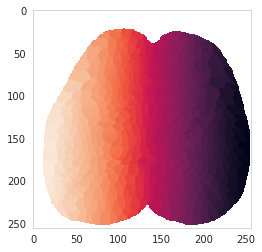

In [7]:
with h5py.File(step_0_root+'idx_sorted_500_cm126.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [8]:
fetch_sensory_path = str(PREPARES / "sensory-boop-test") + "/"
sensory_ind = load_pickle(fetch_sensory_path+'inferred_brightest_ind_'+mouse)
mouth_S1_ind = sensory_ind['mouth']

In [9]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False


In [10]:
# x = scipy.io.loadmat(pupil_path)
# pupil = np.empty((35941,0))
# pupil_p = np.empty((35941,0))
# for key in ['Top']+['TopR']+['Right']+['BottomR']+['Bottom']+['BottomL']+['Left']+['TopL']+['Eyelid']:
#     pupil = np.append(pupil,x[mouse_day+'_'+run][key][0,0][:,:2],axis=1)
#     pupil_p = np.append(pupil_p,x[mouse_day+'_'+run][key][0,0][:,2:3],axis=1)

# pupil_p_value = np.mean(pupil_p,axis=1)

# pca = PCA(n_components=1)
# pupil_pc = pca.fit_transform(pupil)  
# df = pd.DataFrame(pupil_pc).copy()
# df.iloc[pupil_p_value < 0.7]=np.nan
# df.iloc[0,0]=0
# pupil_pc = np.array(df.interpolate())
# pupil_pc = np.mean(pupil_pc[:-1].reshape((-1,3)),axis=1)
# pupil_pc = -pupil_pc[500:-505]
# pupil_pc = stats.zscore(pupil_pc)
# pupil_p_value = np.mean(pupil_p_value[:-1].reshape((-1,3)),axis=1)
# pupil_p_value = pupil_p_value[500:-505]

In [18]:
B.keys()

<KeysViewHDF5 ['cm124_1_runB', 'cm124_1_runC', 'cm124_1_runE', 'cm124_1_runH', 'cm124_1_runJ', 'cm124_2_runB', 'cm124_2_runD', 'cm124_2_runE', 'cm124_2_runF', 'cm124_2_runG', 'cm124_2_runH', 'cm124_2_runI', 'cm124_2_runJ', 'cm125_1_runB', 'cm125_1_runC', 'cm125_1_runD', 'cm125_1_runE', 'cm125_1_runF', 'cm125_1_runG', 'cm125_1_runI', 'cm125_1_runJ', 'cm125_2_runB', 'cm125_2_runC', 'cm125_2_runD', 'cm125_2_runF', 'cm125_2_runG', 'cm125_2_runH', 'cm125_2_runI', 'cm125_2_runJ', 'cm125_3_runB', 'cm125_3_runC', 'cm125_3_runD', 'cm125_3_runE', 'cm125_3_runF', 'cm125_3_runG', 'cm125_3_runH', 'cm125_3_runI', 'cm125_3_runJ', 'cm125_4_runB', 'cm125_4_runC', 'cm125_4_runD', 'cm125_4_runH', 'cm125_4_runI', 'cm125_5_runB', 'cm125_5_runC', 'cm125_5_runD', 'cm125_5_runH', 'cm125_5_runI', 'cm125_6_runB', 'cm125_6_runC', 'cm125_6_runD', 'cm125_6_runH', 'cm125_6_runI', 'cm125_6_runJ', 'cm126_1_runB', 'cm126_1_runC', 'cm126_1_runD', 'cm126_1_runE', 'cm126_1_runF', 'cm126_1_runG', 'cm126_1_runH', 'cm126_1_

cm126_3_runG use pupil PC
cm126_3_runE use pupil PC
cm126_3_runF use pupil PC
cm126_5_runG use pupil PC
cm126_5_runE use pupil PC
cm126_5_runF use pupil PC


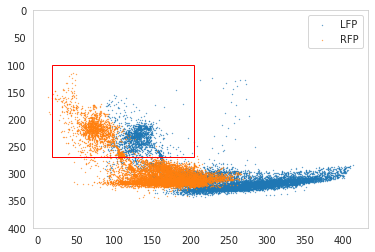

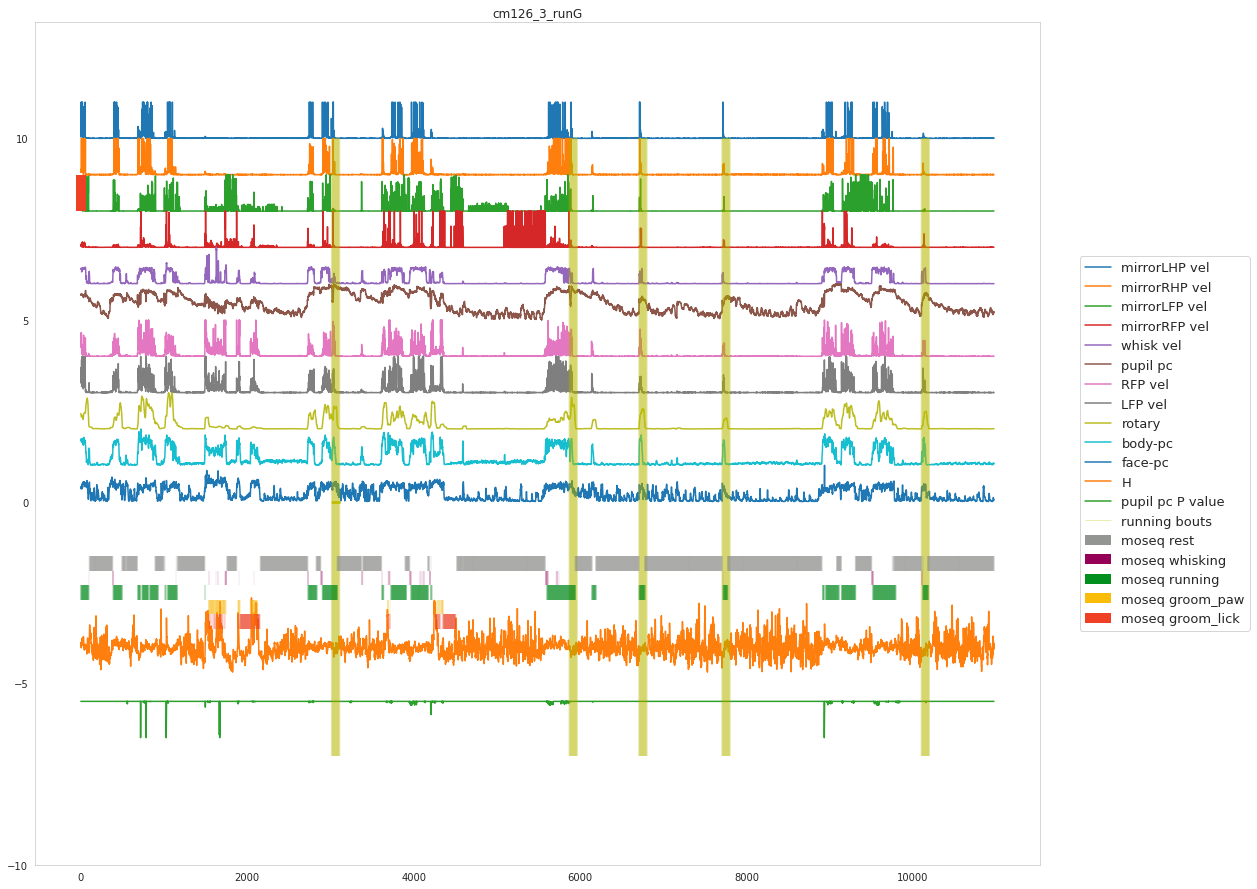

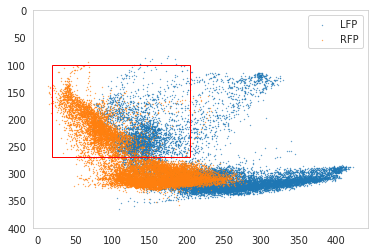

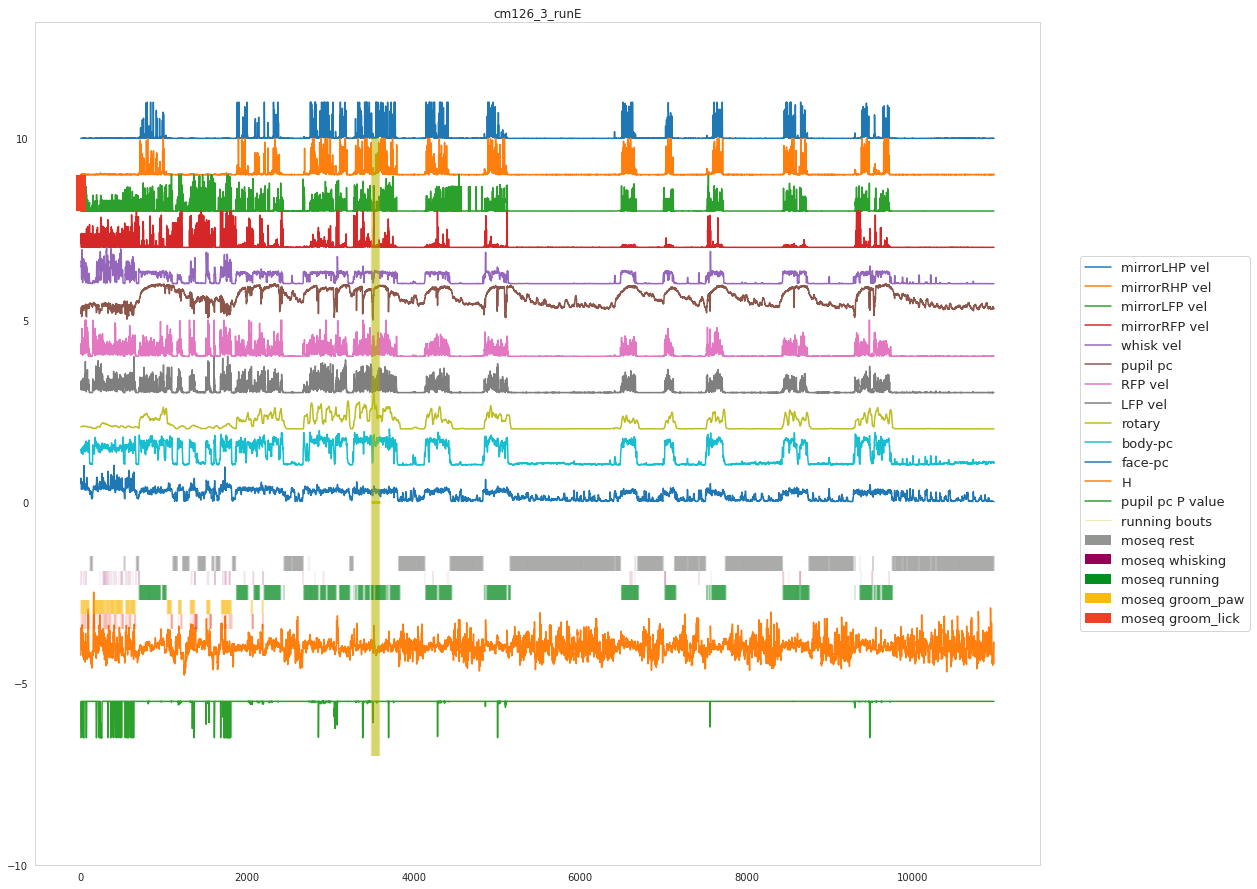

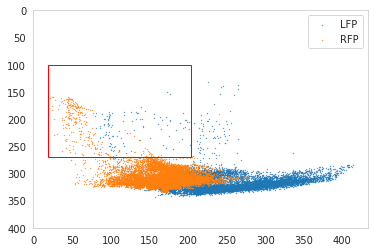

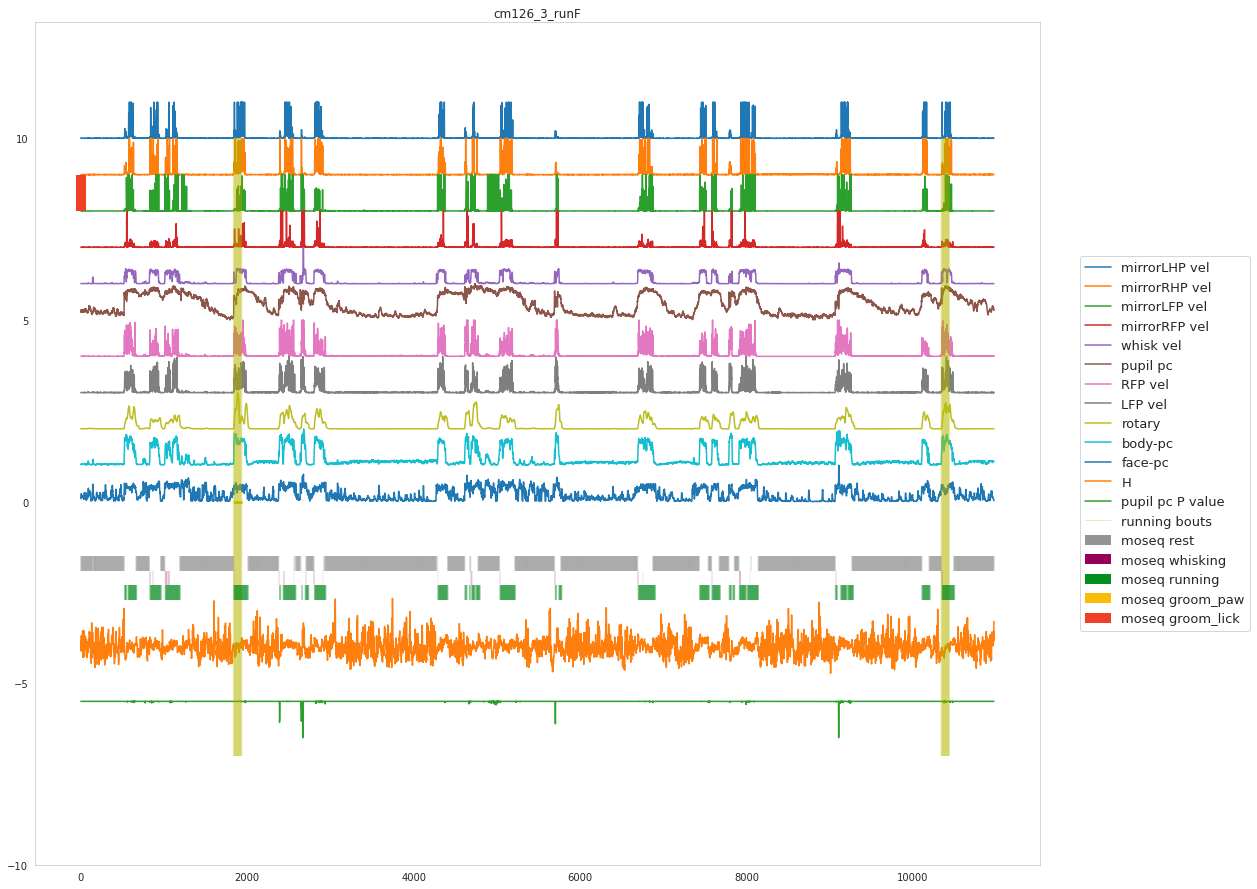

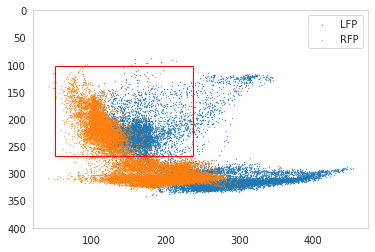

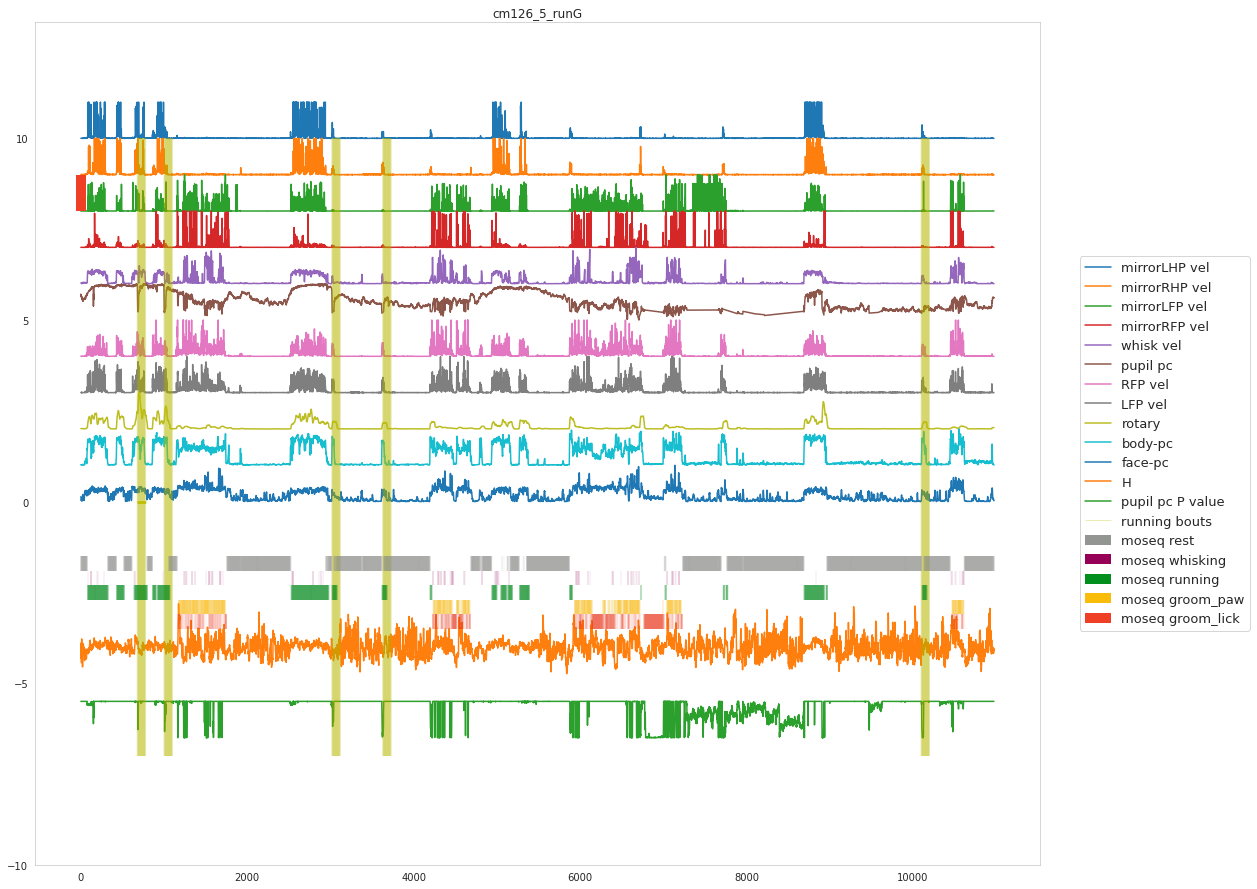

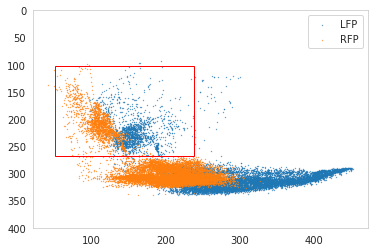

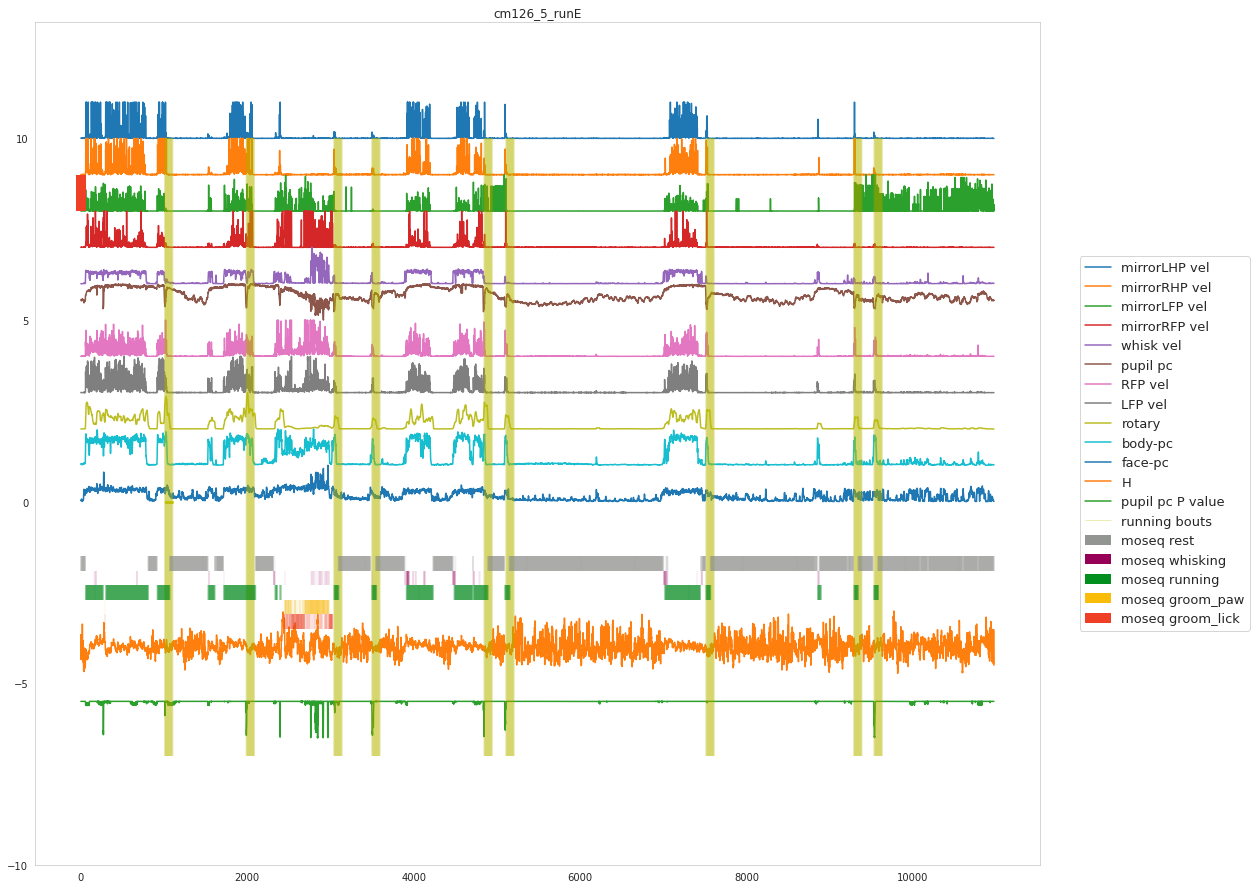

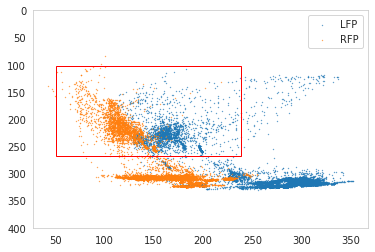

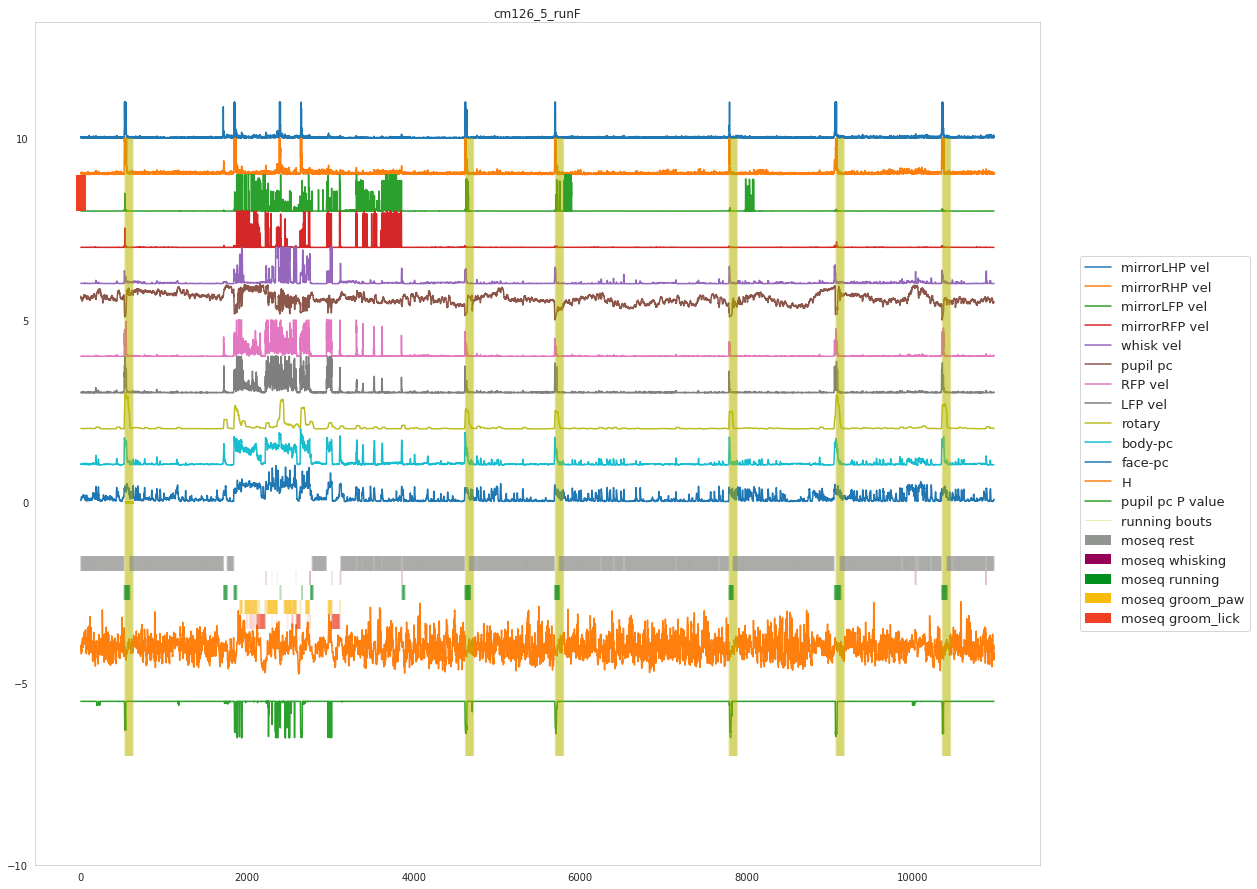

In [21]:
sns.set_style("whitegrid", {'axes.grid' : False})
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

num_regions=500
T_PRE = 100
T_POST = 100
T = T_PRE+T_POST

M_jrgeco = np.empty((num_regions,T,0))
# M_chbt = np.empty((num_regions,T,0))
# M_chbt_std = np.empty((num_regions,T,0))
M_rotf = np.empty((T,0))
M_rotf_raw = np.empty((T,0))
M_pupil_pc = np.empty((T,0))
M_pupil_pc_norm = np.empty((T,0))
M_face_pc = np.empty((T,0))
M_body_pc = np.empty((T,0))
M_whisk_vel = np.empty((T,0))
M_whisk_vel_norm = np.empty((T,0))
M_nose_vel = np.empty((T,0))
M_nose_vel_norm = np.empty((T,0))
M_pupil_p_value = np.empty((T,0))
M_day_label = np.empty((0))
M_is_groom = np.empty((T,0))
M_ind = np.empty((0))
M_ind_stop = np.empty((0))
M_y_rise_LFP = np.empty((T,0))
M_y_rise_LFP_raw = np.empty((T,0))
M_LFP_vel = np.empty((T,0))
M_LFP_vel_norm = np.empty((T,0))
M_RFP_vel = np.empty((T,0))
M_RFP_vel_norm = np.empty((T,0))

M_mirrorRFP_vel = np.empty((T,0))
M_mirrorRFP_vel_norm = np.empty((T,0))
M_mirrorLFP_vel = np.empty((T,0))
M_mirrorLFP_vel_norm = np.empty((T,0))
M_mirrorRHP_vel = np.empty((T,0))
M_mirrorRHP_vel_norm = np.empty((T,0))
M_mirrorLHP_vel = np.empty((T,0))
M_mirrorLHP_vel_norm = np.empty((T,0))



data_joint=pd.DataFrame()
big_df_concat = pd.DataFrame()

for i_file,fname in enumerate(file_spont): 
    
    ################################### identity 
    run_name = fname.split('_stim_1')[0][-4:]
    day = fname.split('step_2/'+mouse+'/')[1][:1]
    mouse_day = mouse+'_'+day
    run=run_name

    with h5py.File(fname,'r') as f_H: 
        H = np.array(f_H['H']).transpose() #(36,11975)    
        H = H[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

#         H_filt={}
#         H_filt_temp=f_H['H_filt']
#         for i_key, key in enumerate(H_filt_temp.keys()):
#             H_filt[key] = np.array(H_filt_temp[key]).transpose()[:,500:-505]

    # load pupil 
    try:
        try:
            pupil_temp=B[mouse_day+'_'+run]
            pupil_pc = stats.zscore(np.array(pd.DataFrame(np.squeeze(pupil_temp['pupil'])[500:-505]).interpolate()))
            print(mouse_day+'_'+run,'use pupil size')
        except:
            print(mouse_day+'_'+run,'use pupil PC')
            x = scipy.io.loadmat(pupil_path)
            pupil = np.empty((35941,0))
            pupil_p = np.empty((35941,0))
            for key in ['Top']+['TopR']+['Right']+['BottomR']+['Bottom']+['BottomL']+['Left']+['TopL']+['Eyelid']:
                pupil = np.append(pupil,x[mouse_day+'_'+run][key][0,0][:,:2],axis=1)
                pupil_p = np.append(pupil_p,x[mouse_day+'_'+run][key][0,0][:,2:3],axis=1)

            pupil_p_value = np.mean(pupil_p,axis=1)

            pca = PCA(n_components=1)
            pupil_pc = pca.fit_transform(pupil)  
            df = pd.DataFrame(pupil_pc).copy()
            df.iloc[pupil_p_value < 0.99]=np.nan
            df.iloc[0,0]=0
            
            pupil_pc = np.array(df.interpolate())
            pupil_pc = np.mean(pupil_pc[:-1].reshape((-1,3)),axis=1)
            pupil_pc = -pupil_pc[500:-505]
            pupil_pc = stats.zscore(pupil_pc)
            pupil_p_value = np.mean(pupil_p_value[:-1].reshape((-1,3)),axis=1)
            pupil_p_value = pupil_p_value[500:-505]
    except:
        print('pupil missing ',mouse_day+'_'+run)
        continue
    
    
    ################################### whisking velocity (11980,)
    try:
        f_name_dlc = glob.glob(whisk_dlc_root+'face/' + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        prominent_whiskers=bodyparts[7:] #plot most prominent whiskers

        vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(prominent_whiskers):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel_df[bpt] = vel
        mean_vel = vel_df.mean(axis=1)
        smooth_mean_vel = mean_vel.rolling(15).std()
        smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        whisk_vel = smooth_mean_vel_ds[500:-505]
        #
        nose_pts=bodyparts[:7]
        nose_vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(nose_pts):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            nose_vel_df[bpt] = vel
        mean_nose_vel = nose_vel_df.mean(axis=1)
        smooth_mean_nose_vel = mean_nose_vel.rolling(15).std() # smooth
        smooth_mean_nose_vel_ds = np.mean(smooth_mean_nose_vel[:-1].values.reshape((-1,3)),axis=1)
        nose_vel = smooth_mean_nose_vel_ds[500:-505]

    except:
        print('whisking velocity missing ',mouse_day+'_'+run)
        continue
        
    try:
        with(h5py.File(pjoin('/home/wx2203/RS_analysis/behavior',
                             mouse,day,run+'_cam_pc.mat'),'r')) as f_b:
            motionS = f_b['motionS']# this is the HDF5 reference
            motion_pc = {key: [] for key in list(motionS.keys())} 
            for key in list(motionS.keys()):
                motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
                motion_pc[key]= motion_pc[key].iloc[:,:-5]
                
                motion_pc[key] = motion_pc[key].T.rolling(window=5).std().T
                motion_pc[key]=motion_pc[key].iloc[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    except:
        continue

        
    # try:    
    f_config = h5py.File(config_root+'groom_config_'+mouse+'.mat','r')

    x_top_left = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,0]
    x_botton_right = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,1]
    y_top_left = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,0]
    y_botton_right = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,1]

    out_h = int((x_botton_right - x_top_left)/3)
    out_w = int((y_botton_right - y_top_left)/3) 
    y = int(x_top_left/3)
    x = int(y_top_left/3)

    f_name_dlc = glob.glob(groom_dlc_root +mouse+'/'+ mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
    for i_bpt,bpt in enumerate(bodyparts):

        p_value = new_df[bpt]['likelihood']
        new_df[bpt]['x'][p_value<0.1]=np.nan
        new_df[bpt]['y'][p_value<0.1]=np.nan
        new_df[bpt] = new_df[bpt].interpolate()
        new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
        vel = pd.DataFrame(vel)#.rolling(30).std()
        vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
        paws_vel_df[bpt] = vel[500:-505]
    LFP_vel = np.array(paws_vel_df['LFP'])
    RFP_vel = np.array(paws_vel_df['RFP'])


    fig,ax = plt.subplots(1)
    plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
    plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
    rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
    plt.ylim([0,400])
    plt.legend()
    ax.add_patch(rect)
    plt.gca().invert_yaxis()

    rise_LFP = new_df['LFP']['y'].copy().diff().rolling(5).std().rolling(3).mean()
    rise_LFP = np.mean(rise_LFP[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    rise_LFP = rise_LFP[500:-505] 
    # rise_LFP = normalize(stats.zscore(rise_LFP[500:-505]))

    rise_LFP_raw = new_df['LFP']['y'].copy().diff()
    rise_LFP_raw = np.mean(rise_LFP_raw[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    rise_LFP_raw = rise_LFP_raw[500:-505]   

    is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
    is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
    is_groom = np.logical_or(is_groom_LFP,is_groom_RFP)
    is_groom_smooth = is_groom.rolling(50).mean()

    is_groom_smooth_ds = np.mean(is_groom_smooth[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

    #downsample
    new_df = new_df[:-1].groupby(np.arange(new_df[:-1].shape[0])//3, axis=0).mean()
    df_cam0 = new_df.iloc[500:-505]


#     except:
#         print('grooming missing ',mouse_day+'_'+run)   
#         continue
        
    try:
        paws_vel_df = pd.DataFrame()
        f_name_dlc = glob.glob(mirror_dlc_root + mouse_day[2:]+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        #     bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        bodyparts=['LFP','RFP','LHP','RHP']
        for i_bpt,bpt in enumerate(bodyparts):
            p_value = new_df[bpt]['likelihood']
            new_df[bpt]['x'][p_value<0.1]=np.nan
            new_df[bpt]['y'][p_value<0.1]=np.nan
            new_df[bpt] = new_df[bpt].interpolate()
            new_df[bpt] = new_df[bpt].fillna(0) # nan appears in first few rows
            
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel)#.rolling(60).mean()
            vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        mirrorLFP_vel = np.array(paws_vel_df['LFP'])
        mirrorRFP_vel = np.array(paws_vel_df['RFP'])
        mirrorLHP_vel = np.array(paws_vel_df['LHP'])
        mirrorRHP_vel = np.array(paws_vel_df['RHP'])
        #downsample
        new_df = new_df[:-1].groupby(np.arange(new_df[:-1].shape[0])//3, axis=0).mean()
        df_cam1 = new_df.iloc[500:-505]

    except:
        print('mirror paws velocity missing ',mouse_day+'_'+run)
        continue        
        
    data_pot = pd.concat([df_cam0,df_cam1],
                         keys=['cam0','cam1'],names=['column_level'],axis=1)
    
    face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
    face_pc = np.array(stats.zscore(face_pc))
    body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
    body_pc = np.array(stats.zscore(body_pc))   
    whisk_vel_norm = stats.zscore(whisk_vel)
    nose_vel_norm = stats.zscore(nose_vel)
    pupil_pc_norm = stats.zscore(pupil_pc)
    LFP_vel_norm = stats.zscore(LFP_vel)
    RFP_vel_norm = stats.zscore(RFP_vel)    
    mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
    mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
    mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
    mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)
    data_pot = pd.concat([df_cam0,df_cam1],
                         keys=['cam0','cam1'],names=['column_level'],axis=1)
    # remove extreme values
    threshold = 7
    face_pc[face_pc>threshold]=threshold
    body_pc[body_pc>threshold]=threshold
    whisk_vel_norm[whisk_vel_norm>threshold]=threshold
    nose_vel_norm[nose_vel_norm>threshold]=threshold
    LFP_vel_norm[LFP_vel_norm>threshold]=threshold
    RFP_vel_norm[RFP_vel_norm>threshold]=threshold
    mirrorLFP_vel_norm[mirrorLFP_vel_norm>threshold]=threshold
    mirrorRFP_vel_norm[mirrorRFP_vel_norm>threshold]=threshold
    mirrorLHP_vel_norm[mirrorLHP_vel_norm>threshold]=threshold
    mirrorRHP_vel_norm[mirrorRHP_vel_norm>threshold]=threshold
    
    ################################### rotary (11980, 1)
    try:
        with h5py.File(rotary_root+mouse_day+'_'+run+'_H.mat','r') as f_rot:
            rotf = pd.DataFrame((f_rot['rotf']))#.rolling(window=30,axis=0).std()
            rotf = rotf.iloc[500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming   
            rot_raw = np.array(stats.zscore(rotf))
            
            rotf = pd.DataFrame((f_rot['rotf'])).rolling(window=40,axis=0).std()
            rotf = rotf.iloc[500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming   
            rot_smooth = np.array(stats.zscore(rotf))
    except:
        print('rotf missing ',mouse_day+'_'+run,' ')
        # No rotf file found? Use LFP_vel_norm instead..
        # rotf = LFP_vel_norm.copy()
        continue

    try:
        big_df = pd.DataFrame()
        all_bev = ['face_pc','body_pc','whisk_vel_norm','nose_vel_norm',
                  'pupil_pc_norm','LFP_vel_norm','RFP_vel_norm','mirrorLFP_vel_norm',
                  'mirrorRFP_vel_norm','mirrorLHP_vel_norm','mirrorRHP_vel_norm',
                  'rot_raw','rot_smooth']
        for bev in all_bev:
            exec("big_df[bev] = normalize({})".format(bev))
        big_df['rise_LFP']=rise_LFP
        big_df['is_groom_smooth_ds']=is_groom_smooth_ds
    except:
        print('big df issue ',mouse_day+'_'+run,' ')
        continue
    #behavior segmentation
    is_whisking = np.logical_and(np.logical_and(big_df['whisk_vel_norm']>0.3, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_smooth']<0.2)
    # is_reach = big_df['rise_LFP']>22
    
    is_running = np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['rot_smooth']>0.1)
    
    is_groom_paw = np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
                              big_df['LFP_vel_norm']>0.1),big_df['rot_smooth']<0.2)
    is_groom_lick = np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_smooth']<0.2)   
    is_rest = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_smooth']<0.2),big_df['whisk_vel_norm']<0.1)
    
    moseq_list = ['is_rest','is_whisking','is_running','is_groom_paw','is_groom_lick']
    for moseq in moseq_list:
        exec("big_df[moseq] = {}".format(moseq))

        
    stimframes_root = prefix+'/users/wx2203/H_new/'
    f = scipy.io.loadmat(stimframes_root+mouse_day+'_'+run+'_H.mat')
    m = f['m']
    stimframes = np.squeeze(m['stimframes'][0,0])
    stimframes = stimframes -500
    stimframes = stimframes[stimframes>0] 
    stimframes = stimframes[stimframes<10375]
        # except:
        #     print('stimframes bug ',mouse,day,'H_'+run+'_stim_1.mat')
        #     continue
        
        
        


    start_stop_ind = pd.DataFrame(np.stack((stimframes,stimframes+T_POST)).T)
    
    is_groom_start_stop = start_stop(np.squeeze(is_groom_smooth_ds>0.3),trigger_val = True)
    
    temp = []
    for i in range(len(start_stop_ind)):
        x1 = start_stop_ind.iloc[i,0];x2 = start_stop_ind.iloc[i,1];
        temp.append(any(max(x1,lower) <= min(x2,upper) for (lower, upper) in list(is_groom_start_stop)))
    start_stop_ind['is_in_groom']=temp
    start_stop_ind = start_stop_ind[start_stop_ind['is_in_groom']==False]


        
    tmp = pd.concat([big_df], keys=[mouse_day+'_'+run], names=['row_level'])
    big_df_concat = pd.concat([big_df_concat, tmp])


    plt.figure(figsize=(18,15.5))
    plt.plot(normalize(mirrorLHP_vel_norm)+10,label='mirrorLHP vel')   
    plt.plot(normalize(mirrorRHP_vel_norm)+9,label='mirrorRHP vel') 
    plt.plot(normalize(mirrorLFP_vel_norm)+8,label='mirrorLFP vel') 
    plt.plot(normalize(mirrorRFP_vel_norm)+7,label='mirrorRFP vel') 
    
    plt.plot(normalize(whisk_vel_norm)+6,label='whisk vel') 
    plt.plot(normalize(pupil_pc_norm)+5,label='pupil pc')                           
    plt.plot(normalize(RFP_vel_norm)+4,label='RFP vel')            
    plt.plot(normalize(LFP_vel_norm)+3,label='LFP vel')
    plt.plot(normalize(rot_smooth)+2,label='rotary')
    # plt.plot(normalize(face_pc)+1,label='face-pc')
    plt.plot(normalize(body_pc)+1,label='body-pc')
    plt.plot(normalize(face_pc),label='face-pc')
    # plt.plot(normalize(rise_LFP_raw)-1,label='rise LFP in y')
    plt.plot(H[mouth_S1_ind,:]*9-4,label='H')
    
    plt.plot(pupil_p_value-6.5,label='pupil pc P value')  
    
    try:
        for i in range(len(start_stop_ind)):
            plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,1]),
                       -7, 10,linewidth = 0.2,color='y',alpha=0.3)
        plt.vlines(range(start_stop_ind.iloc[0,0],start_stop_ind.iloc[0,1]),
                       -0.05, 0.01,linewidth = 1,color='y',alpha=0.3,label='running bouts')
    except:
        print('NO start stop  ',mouse_day+'_'+run,' ')
        continue
    # for i_key, key in enumerate(H_filt.keys()):
    #     plt.plot(H_filt[key][mouth_S1_ind,:]*9-5-i_key,label="{:.2f}-{:.2f} HZ".format(spectrum[i_key,0],spectrum[i_key,1]))       
    
    col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
    col_list_palette = sns.xkcd_palette(col_list)


    # moseq
    for i, moseq in enumerate(moseq_list):
        plt.vlines(np.where(big_df[moseq]==True), -1.5-i*0.4, -1.9-i*0.4,linewidth=0.1,color=col_list_palette[i])
        plt.vlines(0, 8, 9,linewidth=10,color=col_list_palette[i],label='moseq '+moseq[3:])#for the legend

    plt.ylim([-10,13.2])
    plt.title(mouse_day+'_'+run_name)
    plt.legend(bbox_to_anchor=(1.04,0.5), loc="center left", borderaxespad=0,fontsize = 13)


    for i in range(len(start_stop_ind)):
        M_jrgeco = np.append(M_jrgeco,H[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        # M_jrgeco_std = np.append(M_jrgeco_std,H_std[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        # M_chbt = np.append(M_chbt,H_chbt[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        # M_chbt_std = np.append(M_chbt_std,H_chbt_std[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)

        M_rotf_raw = np.append(M_rotf_raw,rot_raw[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_rotf = np.append(M_rotf,rot_smooth[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_pupil_pc = np.append(M_pupil_pc,pupil_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_face_pc = np.append(M_face_pc,face_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_body_pc = np.append(M_body_pc,body_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_whisk_vel = np.append(M_whisk_vel,whisk_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_whisk_vel_norm = np.append(M_whisk_vel_norm,whisk_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_nose_vel = np.append(M_nose_vel,nose_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_nose_vel_norm = np.append(M_nose_vel_norm,nose_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_LFP_vel = np.append(M_LFP_vel,LFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_LFP_vel_norm = np.append(M_LFP_vel_norm,LFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel = np.append(M_RFP_vel,RFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel_norm = np.append(M_RFP_vel_norm,RFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_pupil_pc_norm = np.append(M_pupil_pc_norm,pupil_pc_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)        
        # M_pupil_p_value = np.append(M_pupil_p_value,pupil_p_value[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)

        i_bout = M_jrgeco.shape[-1]-1        
        tmp = data_pot[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST]
        tmp = pd.concat([tmp], keys=[i_bout], names=['row_level'])
        data_joint = pd.concat([data_joint, tmp])
        
        
        M_mirrorLFP_vel = np.append(M_mirrorLFP_vel,mirrorLFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLFP_vel_norm = np.append(M_mirrorLFP_vel_norm,mirrorLFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel = np.append(M_mirrorRFP_vel,mirrorRFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRFP_vel_norm = np.append(M_mirrorRFP_vel_norm,mirrorRFP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel = np.append(M_mirrorLHP_vel,mirrorLHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorLHP_vel_norm = np.append(M_mirrorLHP_vel_norm,mirrorLHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel = np.append(M_mirrorRHP_vel,mirrorRHP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_mirrorRHP_vel_norm = np.append(M_mirrorRHP_vel_norm,mirrorRHP_vel_norm[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)


        M_is_groom = np.append(M_is_groom,is_groom_smooth_ds[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_ind = np.append(M_ind,start_stop_ind.iloc[i,0]*3+1500)
        M_ind_stop = np.append(M_ind_stop,start_stop_ind.iloc[i,1]*3+1500)
        M_day_label = np.append(M_day_label,mouse_day+'_'+run)
        M_y_rise_LFP = np.append(M_y_rise_LFP,rise_LFP[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_y_rise_LFP_raw = np.append(M_y_rise_LFP_raw,rise_LFP_raw[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
   

In [22]:
M_jrgeco.shape

(500, 200, 28)

# SAVE

In [23]:
scipy.io.savemat(prefix+'users/wx2203/new_analysis_locker/pub-locker/acadia-figures/efigure2/fig-data/'+'STIM_'+mouse+'_raw.mat',
                       {'M_jrgeco':M_jrgeco,
                        'M_rotf':M_rotf,
                        'M_rotf_raw':M_rotf_raw,
                        'M_face_pc':M_face_pc,
                        'M_body_pc':M_body_pc,
                        'M_pupil_pc':M_pupil_pc,
                        'M_pupil_pc_norm':M_pupil_pc_norm,
                        # 'M_pupil_p_value':M_pupil_p_value,
                        'M_whisk_vel':M_whisk_vel,
                        'M_whisk_vel_norm':M_whisk_vel_norm,
                        'M_nose_vel':M_nose_vel,
                        'M_nose_vel_norm':M_nose_vel_norm,
                        'M_LFP_vel':M_LFP_vel,
                        'M_LFP_vel_norm':M_LFP_vel_norm,
                        'M_RFP_vel':M_RFP_vel,
                        'M_RFP_vel_norm':M_RFP_vel_norm,
                       'M_day_label':M_day_label,
                        'M_is_groom':M_is_groom,
                       'M_ind':M_ind,
                           'M_ind_stop':M_ind_stop,
                       'M_y_rise_LFP':M_y_rise_LFP,
                       'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
                       'M_mirrorRFP_vel':M_mirrorRFP_vel,
                       'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
                        'M_mirrorLFP_vel':M_mirrorLFP_vel,
                        'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
                        'M_mirrorRHP_vel':M_mirrorRHP_vel,
                        'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
                        'M_mirrorLHP_vel':M_mirrorLHP_vel,
                        'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm
                       })



save_pickle(data_joint,prefix+'users/wx2203/new_analysis_locker/pub-locker/acadia-figures/efigure2/fig-data/'+'STIM_'+mouse+'_raw_data_joint')


# now make figure

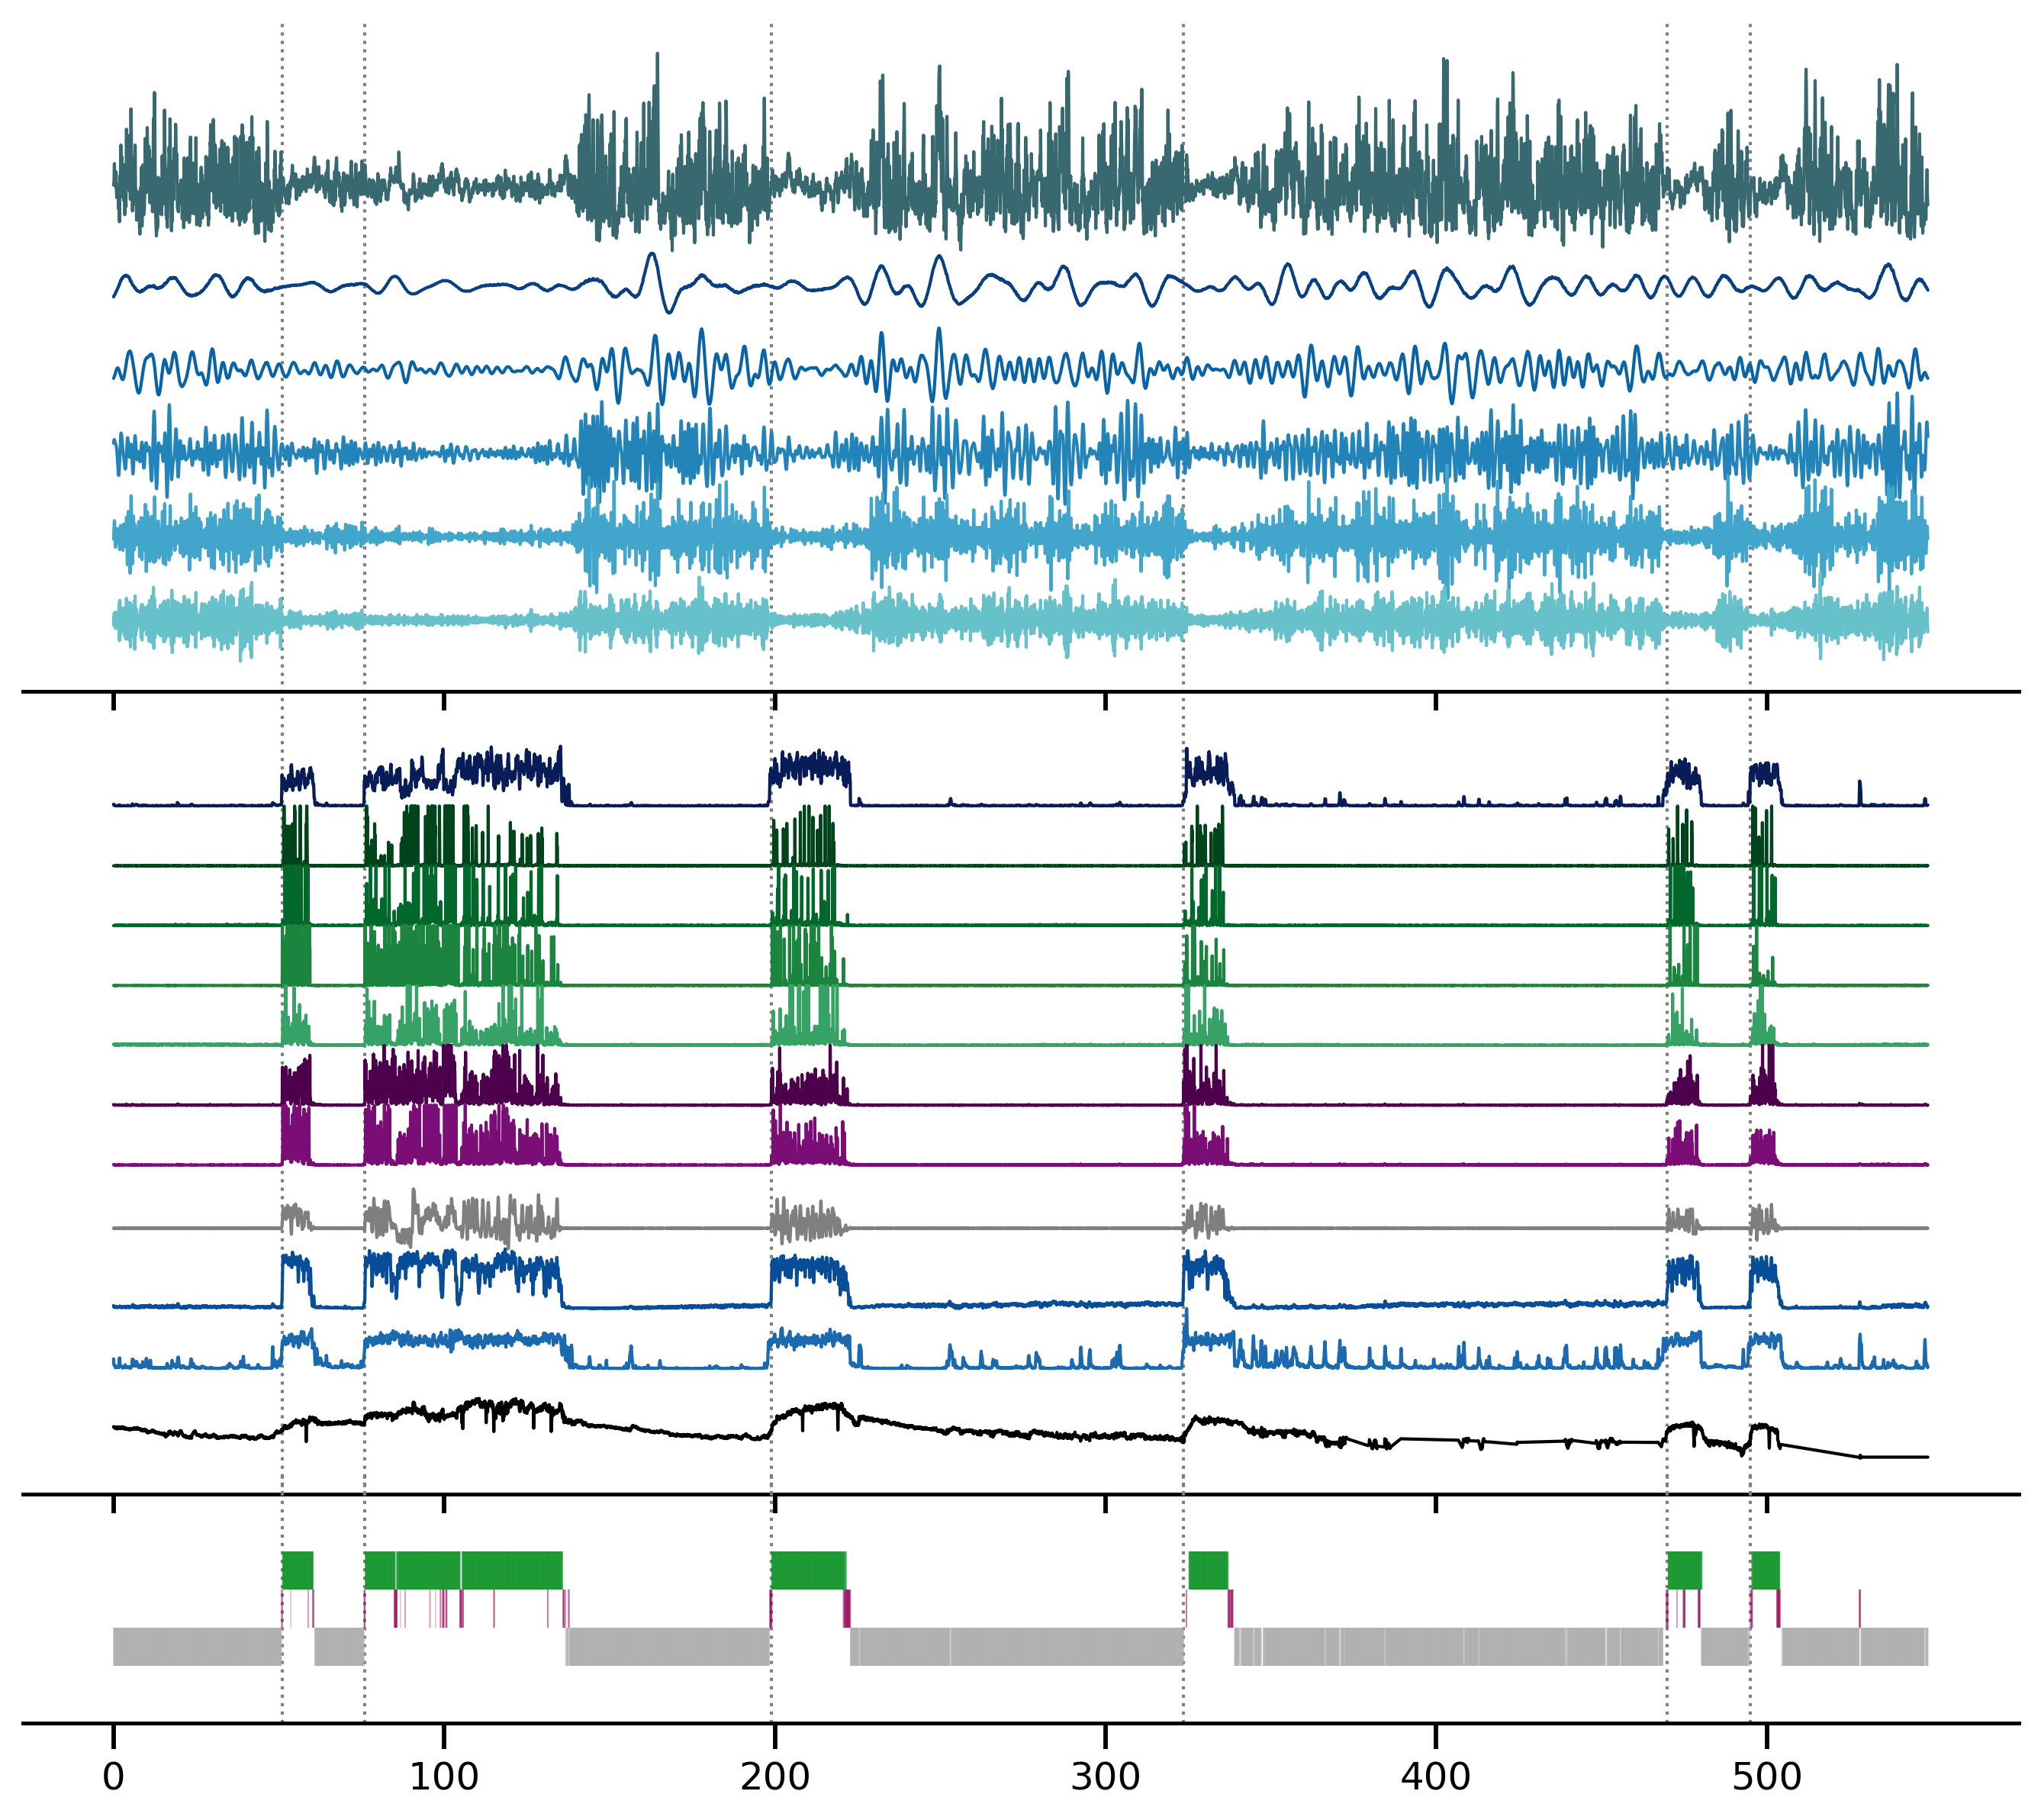

In [190]:

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams["axes.linewidth"] = 1
# plt.rcParams["patch.linewidth"] = 6
with plt.style.context('default'):
    fig = plt.figure(figsize=(7.5*1.5,7*1.5),dpi=300)
    gs = fig.add_gridspec(16,10)
    ax1 = fig.add_subplot(gs[:6, :])
    ax2 = fig.add_subplot(gs[6:13, :])
    ax3 = fig.add_subplot(gs[13:15, :])


    lw = 1
    import matplotlib
    cmap = plt.cm.get_cmap('GnBu', 10)
    palatte_1 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    cmap = plt.cm.get_cmap('BuGn', 10)
    palatte_2 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    cmap = plt.cm.get_cmap('YlGnBu', 10)
    palatte_3 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    cmap = plt.cm.get_cmap('BuPu', 10)
    palatte_4 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    cmap = plt.cm.get_cmap('Blues', 10)
    palatte_5 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    
    palatte_6 = ['#cf9d3a','#345641','#802215','#ad3725','#315042','#315042','#315042']
    palatte_6 = ['darkgray',col_list_palette[1],col_list_palette[2],'#345641',
                 '#802215','#ad3725','#315042','#315042','#315042']
    t_tc = np.divide(range(pupil_pc_norm.shape[0]),20)

    ax1.plot(t_tc,H[mouth_S1_ind,:]*9,label='H',linewidth=lw,color='#396970')
    for i_key, key in enumerate(H_filt.keys()):
        ax1.plot(t_tc,H_filt[key][mouth_S1_ind,:]*9-1.2-i_key,color=color_list[-(i_key+1)],linewidth=lw,
                 label="{:.2f}-{:.2f} HZ".format(spectrum[i_key,0],spectrum[i_key,1]))       

    # ax1.axis('off');ax2.axis('off');ax3.tick_params(left=False) 

    ax2.plot(t_tc,normalize(whisk_vel_norm)+11,label='whisk vel',linewidth=lw,color=palatte_3[-1])

    ax2.plot(t_tc,normalize(mirrorLHP_vel_norm)+10,label='mirrorLHP vel',linewidth=lw,color=palatte_2[-1])   
    ax2.plot(t_tc,normalize(mirrorRHP_vel_norm)+9,label='mirrorRHP vel',linewidth=lw,color=palatte_2[-2]) 
    ax2.plot(t_tc,normalize(mirrorLFP_vel_norm)+8,label='mirrorLFP vel',linewidth=lw,color=palatte_2[-3]) 
    ax2.plot(t_tc,normalize(mirrorRFP_vel_norm)+7,label='mirrorRFP vel',linewidth=lw,color=palatte_2[-4]) 

    ax2.plot(t_tc,normalize(RFP_vel_norm)+6,label='RFP vel',linewidth=lw,color=palatte_4[-1])            
    ax2.plot(t_tc,normalize(LFP_vel_norm)+5,label='LFP vel',linewidth=lw,color=palatte_4[-2])


    # ax2.plot(normalize(pupil_pc_norm)+5,label='pupil pc',linewidth=lw)                           

    ax2.plot(t_tc,normalize(rot_raw)+3.6,label='rotary',linewidth=lw,color='tab:gray')


    ax2.plot(t_tc,normalize(body_pc)+2.6,label='body-pc',linewidth=lw,color=palatte_5[-2])
    ax2.plot(t_tc,normalize(face_pc)+1.6,label='face-pc',linewidth=lw,color=palatte_5[-3])
    ax2.plot(t_tc,normalize(pupil_pc_norm)+0.1,label='pupil pc',linewidth=lw,color='black')                           

    for i, moseq in enumerate(moseq_list):
        ax3.vlines(t_tc[np.where(big_df[moseq]==True)], -1.5+i*0.4, -1.9+i*0.4,linewidth=0.1,color=palatte_6[i])
        ax3.vlines(0, 8, 9,linewidth=10,color=palatte_6[i],label='moseq '+moseq[3:])#for the legend
    ax3.set_ylim([-2.5,-0.3])
    ax3.spines['left'].set_visible(False)
    
    # fig, ax1 = sppolish.set_bounds(fig, ax3)  
    for i_start_stop in range(len(start_stop_ind)):
        indd = start_stop_ind.iloc[i_start_stop,0]
        ax1.axvline(x=t_tc[indd],ymin=-0.04,ymax=1,c="tab:gray",linestyle='dotted',linewidth=1,zorder=0, clip_on=False)
        ax2.axvline(x=t_tc[indd],ymin=0,ymax=1,c="tab:gray",linestyle='dotted',linewidth=1,zorder=0, clip_on=False)
        ax3.axvline(x=t_tc[indd],ymin=0,ymax=1.2,c="tab:gray",linestyle='dotted',linewidth=1, zorder=0,clip_on=False)

    ax1.spines['left'].set_visible(False)    
    ax2.spines['left'].set_visible(False)  
    ax1.set_yticks([]);ax2.set_yticks([]);ax3.set_yticks([])

# with annotation

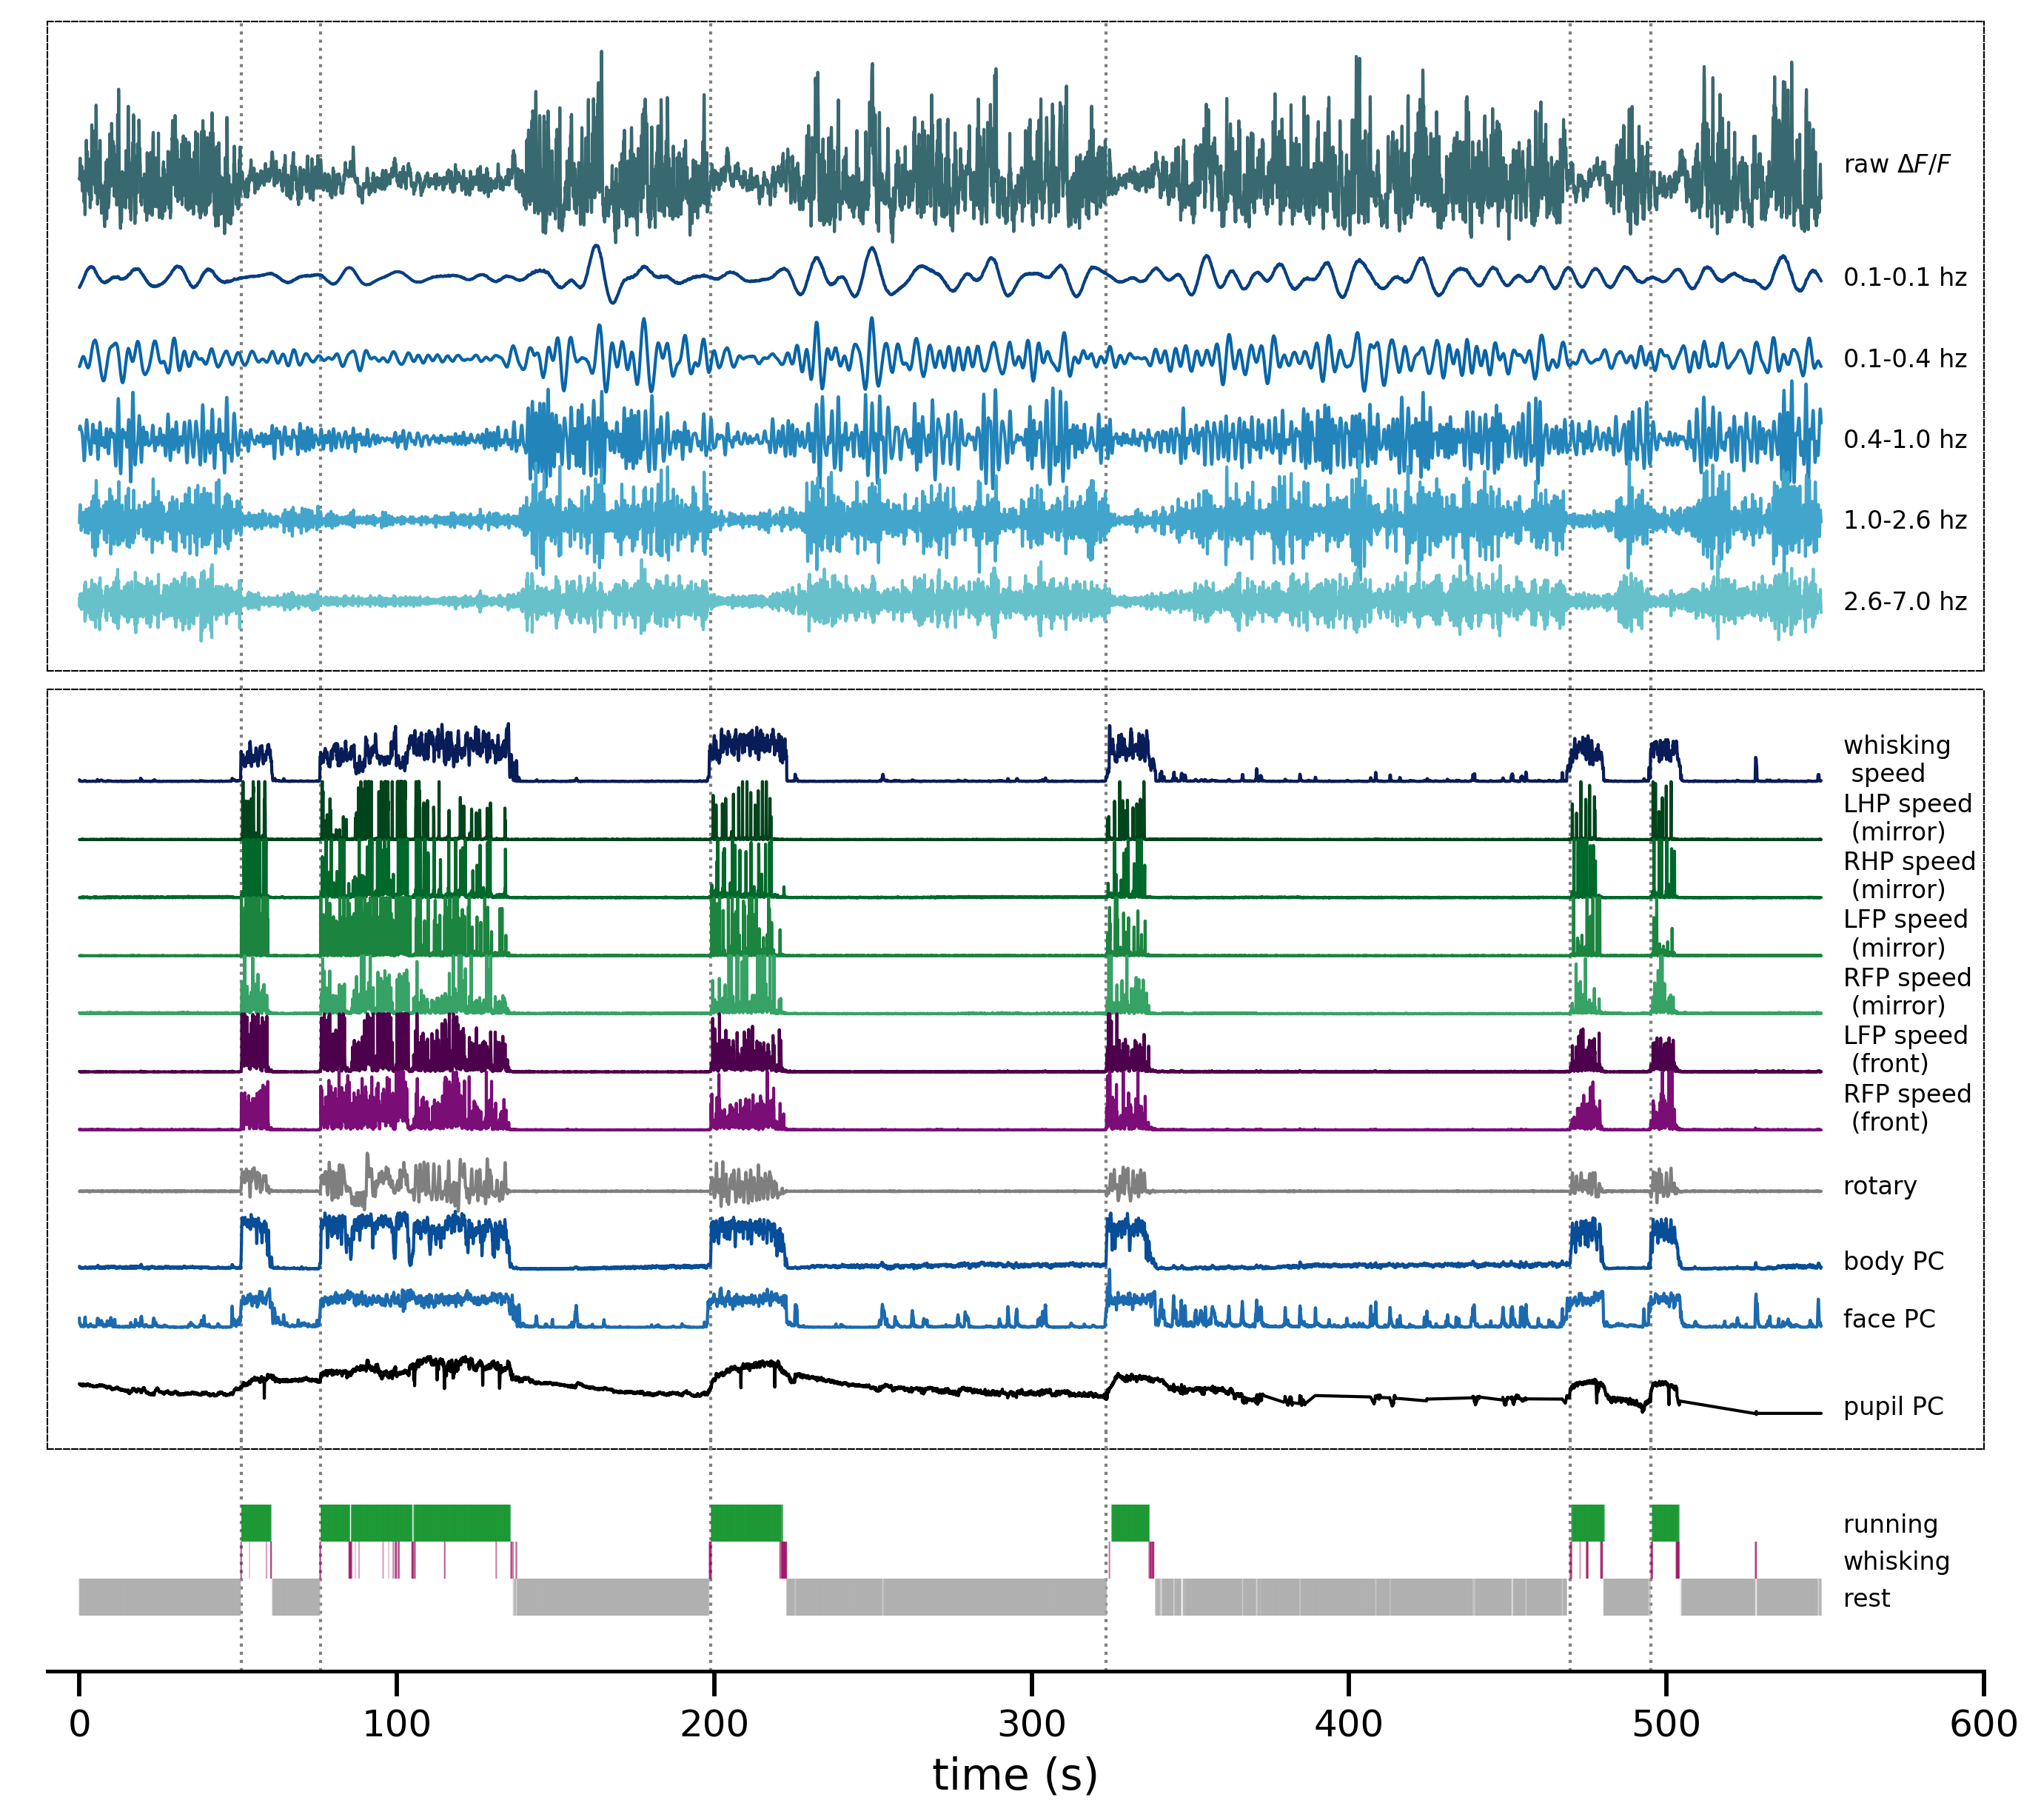

In [221]:

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams["axes.linewidth"] = 1
# plt.rcParams["patch.linewidth"] = 6
with plt.style.context('default'):
    fig = plt.figure(figsize=(7.5*1.5,7*1.5),dpi=300)
    gs = fig.add_gridspec(16,10)
    ax1 = fig.add_subplot(gs[:6, :])
    ax2 = fig.add_subplot(gs[6:13, :])
    ax3 = fig.add_subplot(gs[13:15, :])


    lw = 1
    import matplotlib
    cmap = plt.cm.get_cmap('GnBu', 10)
    palatte_1 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    cmap = plt.cm.get_cmap('BuGn', 10)
    palatte_2 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    cmap = plt.cm.get_cmap('YlGnBu', 10)
    palatte_3 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    cmap = plt.cm.get_cmap('BuPu', 10)
    palatte_4 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    cmap = plt.cm.get_cmap('Blues', 10)
    palatte_5 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
    
    palatte_6 = ['#cf9d3a','#345641','#802215','#ad3725','#315042','#315042','#315042']
    palatte_6 = ['darkgray',col_list_palette[1],col_list_palette[2],'#345641',
                 '#802215','#ad3725','#315042','#315042','#315042']
    t_tc = np.divide(range(pupil_pc_norm.shape[0]),20)

    ax1.plot(t_tc,H[mouth_S1_ind,:]*9,label='H',linewidth=lw,color='#396970')
    ax1.text(t_tc[-1]-t_tc[0]+7,0.1,'raw $\Delta F/F$',color='black',fontsize=8)

    for i_key, key in enumerate(H_filt.keys()):
        label = "{:.1f}-{:.1f} hz".format(spectrum[i_key,0],spectrum[i_key,1])
        ax1.plot(t_tc,H_filt[key][mouth_S1_ind,:]*9-1.2-i_key,color=color_list[-(i_key+1)],linewidth=lw,
                 label=label)   
        ax1.text(t_tc[-1]-t_tc[0]+7,-1.2-i_key-0.1,label,color='black',fontsize=8)

    # ax1.axis('off');ax2.axis('off');ax3.tick_params(left=False) 

    ax2.plot(t_tc,normalize(whisk_vel_norm)+11,label='whisk vel',linewidth=lw,color=palatte_3[-1])
    ax2.text(t_tc[-1]-t_tc[0]+7,11,'whisking \n speed',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(mirrorLHP_vel_norm)+10,label='mirrorLHP vel',linewidth=lw,color=palatte_2[-1])   
    ax2.text(t_tc[-1]-t_tc[0]+7,10,'LHP speed \n (mirror)',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(mirrorRHP_vel_norm)+9,label='mirrorRHP vel',linewidth=lw,color=palatte_2[-2]) 
    ax2.text(t_tc[-1]-t_tc[0]+7,9,'RHP speed \n (mirror)',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(mirrorLFP_vel_norm)+8,label='mirrorLFP vel',linewidth=lw,color=palatte_2[-3]) 
    ax2.text(t_tc[-1]-t_tc[0]+7,8,'LFP speed \n (mirror)',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(mirrorRFP_vel_norm)+7,label='mirrorRFP vel',linewidth=lw,color=palatte_2[-4]) 
    ax2.text(t_tc[-1]-t_tc[0]+7,7,'RFP speed \n (mirror)',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(LFP_vel_norm)+6,label='LFP vel',linewidth=lw,color=palatte_4[-1])            
    ax2.text(t_tc[-1]-t_tc[0]+7,6,'LFP speed \n (front)',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(RFP_vel_norm)+5,label='RFP vel',linewidth=lw,color=palatte_4[-2])
    ax2.text(t_tc[-1]-t_tc[0]+7,5,'RFP speed \n (front)',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(rot_raw)+3.6,label='rotary',linewidth=lw,color='tab:gray')
    ax2.text(t_tc[-1]-t_tc[0]+7,3.9,'rotary',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(body_pc)+2.6,label='body-pc',linewidth=lw,color=palatte_5[-2])
    ax2.text(t_tc[-1]-t_tc[0]+7,2.6,'body PC',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(face_pc)+1.6,label='face-pc',linewidth=lw,color=palatte_5[-3])
    ax2.text(t_tc[-1]-t_tc[0]+7,1.6,'face PC',color='black',fontsize=8)
    ax2.plot(t_tc,normalize(pupil_pc_norm)+0.1,label='pupil pc',linewidth=lw,color='black')                           
    ax2.text(t_tc[-1]-t_tc[0]+7,0.1,'pupil PC',color='black',fontsize=8)

    
    for i, moseq in enumerate(moseq_list):
        ax3.vlines(t_tc[np.where(big_df[moseq]==True)], -1.5+i*0.4, -1.9+i*0.4,linewidth=0.1,color=palatte_6[i])
        ax3.vlines(0, 8, 9,linewidth=10,color=palatte_6[i],label='moseq '+moseq[3:])#for the legend
        if i<3:
            ax3.text(t_tc[-1]-t_tc[0]+7,-1.8+i*0.4,moseq[3:],color='black',fontsize=8)
    ax3.set_ylim([-2.5,-0.3])
    ax3.spines['left'].set_visible(False)
    
    # fig, ax1 = sppolish.set_bounds(fig, ax3)  
    for i_start_stop in range(len(start_stop_ind)):
        indd = start_stop_ind.iloc[i_start_stop,0]
        ax1.axvline(x=t_tc[indd],ymin=-0.04,ymax=1,c="tab:gray",linestyle='dotted',linewidth=1,zorder=0, clip_on=False)
        ax2.axvline(x=t_tc[indd],ymin=0,ymax=1,c="tab:gray",linestyle='dotted',linewidth=1,zorder=0, clip_on=False)
        ax3.axvline(x=t_tc[indd],ymin=0,ymax=1.2,c="tab:gray",linestyle='dotted',linewidth=1, zorder=0,clip_on=False)

    
    ax1.spines['left'].set_visible(True)    
    
    for i_part,part in enumerate(['top','bottom','left','right']):
        ax2.spines[part].set_visible(True)  
        ax2.spines[part].set_linestyle('dashed') 
        ax2.spines[part].set_linewidth(.5) 
        ax1.spines[part].set_visible(True)  
        ax1.spines[part].set_linestyle('dashed') 
        ax1.spines[part].set_linewidth(.5) 
    
    ax1.set_yticks([]);ax2.set_yticks([]);ax3.set_yticks([])
    ax2.set_xticks([]);ax1.set_xticks([])
    ax3.set_xlabel('time (s)')
    for i_ax,ax in enumerate(['1','2','3']):
        exec("ax{}.set_xlim([-10,600])".format(ax))

In [159]:
start_stop(body_pc>0.2,True)

array([[ 1020,  1186],
       [ 1187,  1196],
       [ 1520,  1708],
       [ 1714,  1984],
       [ 1991,  2077],
       [ 2098,  2536],
       [ 2537,  2606],
       [ 2607,  2614],
       [ 2616,  2710],
       [ 3978,  4395],
       [ 4396,  4445],
       [ 6470,  6721],
       [ 6723,  6731],
       [ 6737,  6743],
       [ 6744,  6749],
       [ 9396,  9587],
       [ 9590,  9597],
       [ 9899, 10073]])

In [163]:

# start_stop_ind = start_stop_ind[start_stop_ind[0]>T_PRE+1]
# start_stop_ind = start_stop_ind[start_stop_ind[0]<total_tpt-T_POST-1]

In [164]:
start_stop_ind

,0,1,duration,distance_difference
0,1020,1198,178,1000.0
2,1520,1709,189,308.0
7,3978,4446,468,1268.0
8,6470,6722,252,2024.0
11,9395,9587,192,2645.0
13,9899,10073,174,302.0


In [123]:
big_df[moseq].shape

(10975,)

In [69]:
import matplotlib
cmap = plt.cm.get_cmap('GnBu', 10)
palatte_1 = [matplotlib.colors.rgb2hex(cmap(i)[:3]) for i in range(cmap.N)]
color_list

['#f7fcf0',
 '#e3f4dd',
 '#d0edca',
 '#b4e2ba',
 '#8fd4bd',
 '#67c1cb',
 '#42a6cc',
 '#2384ba',
 '#0864a7',
 '#084081']

In [35]:
save_root = str(PREPARES / "behavior-segment") + "/"
# save_pickle(big_df_concat,save_root+'big_df_concat_'+mouse)

In [55]:
big_df_concat

face_pc   body_pc  whisk_vel_norm  nose_vel_norm  \
row_level                                                               
cm125_3_runG 0      0.241361  0.025528        0.015603       0.145829   
             1      0.342061  0.019103        0.017364       0.144238   
             2      0.358116  0.019194        0.018450       0.182833   
             3      0.408185  0.029218        0.019596       0.196265   
             4      0.420270  0.026962        0.024601       0.200186   
...                      ...       ...             ...            ...   
cm125_2_runB 10970  0.052148  0.007278        0.040534       0.098874   
             10971  0.029464  0.002976        0.039760       0.083985   
             10972  0.027849  0.000961        0.032165       0.078986   
             10973  0.024817  0.001068        0.032170       0.071988   
             10974  0.019359  0.000988        0.031448       0.058615   

                    pupil_pc_norm  LFP_vel_norm  RFP_vel_norm  \
row_level                                                       
cm125_3_runG 0           0.582588      0.004263      0.009193   
             1           0.578768      0.004276      0.009221   
             2           0.589507      0.004266      0.009298   
             3           0.581517      0.004793      0.009319   
             4           0.595146      0.004779      0.009204   
...                           ...           ...           ...   
cm125_2_runB 10970       0.447909      0.002599      0.003328   
             10971       0.428627      0.002362      0.003439   
             10972       0.417665      0.002303      0.003430   
             10973       0.410568      0.002132      0.003115   
             10974       0.397514      0.002072      0.003029   

                    mirrorLFP_vel_norm  mirrorRFP_vel_norm  \
row_level                                                    
cm125_3_runG 0                0.004478            0.005800   
             1                0.004277            0.006084   
             2                0.004021            0.006330   
             3                0.003847            0.006638   
             4                0.003952            0.006719   
...                                ...                 ...   
cm125_2_runB 10970            0.005481            0.010769   
             10971            0.005631            0.010854   
             10972            0.005722            0.011848   
             10973            0.005884            0.011955   
             10974            0.005872            0.012269   

                    mirrorLHP_vel_norm  mirrorRHP_vel_norm   rot_raw  \
row_level                                                              
cm125_3_runG 0                0.006547            0.004363  0.009154   
             1                0.006685            0.004213  0.008852   
             2                0.006458            0.003465  0.008852   
             3                0.006216            0.003351  0.008852   
             4                0.006689            0.003636  0.008852   
...                                ...                 ...       ...   
cm125_2_runB 10970            0.795455            0.012469  0.018706   
             10971            0.808985            0.012226  0.017856   
             10972            0.876326            0.012150  0.017927   
             10973            0.876251            0.011807  0.018001   
             10974            0.889926            0.011101  0.018213   

                    rise_LFP  is_groom_smooth_ds  is_rest  is_whisking  \
row_level                                                                
cm125_3_runG 0      0.283039                 0.0     True        False   
             1      0.316835                 0.0     True        False   
             2      0.066827                 0.0     True        False   
             3      0.154845                 0.0     True        False   
             4      0.273069         

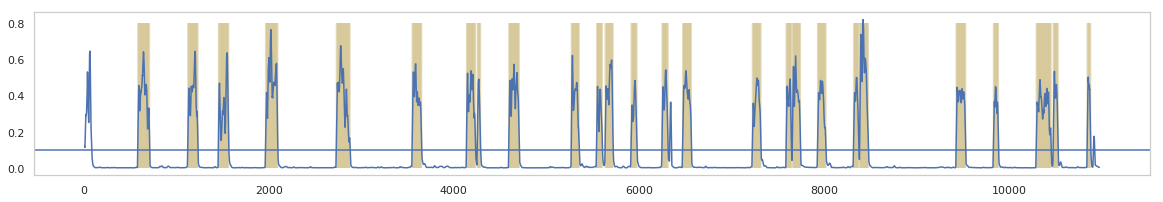

In [59]:
plt.figure(figsize=(20,3))
smoothie = big_df['LFP_vel_norm'].rolling(15).mean()
plt.plot(smoothie)
plt.axhline(0.1)
running_ind=smoothie>0.1

start_stop_ind = pd.DataFrame(start_stop(np.squeeze(running_ind),trigger_val = True))
start_stop_ind['duration'] = start_stop_ind[1]-start_stop_ind[0]
start_stop_ind['distance_difference'] = start_stop_ind[0] - start_stop_ind[1].shift(1)
start_stop_ind = start_stop_ind[start_stop_ind[0]>20+1]
start_stop_ind = start_stop_ind[start_stop_ind[0]<10970]


start_stop_ind = start_stop_ind[start_stop_ind['distance_difference']>2]
start_stop_ind = start_stop_ind[start_stop_ind['duration']>30]

for i in range(len(start_stop_ind)):
    plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,1]),
               -0, 0.8,linewidth = 0.2,color='y',alpha=0.5)
# plt.xlim([8000,10000])

In [31]:
temp_df_concat =load_pickle(save_root+'big_df_concat_'+mouse)

In [32]:
temp_df_concat

face_pc   body_pc  whisk_vel_norm  nose_vel_norm  \
row_level                                                               
cm125_3_runG 0      0.241361  0.025528        0.015603       0.145829   
             1      0.342061  0.019103        0.017364       0.144238   
             2      0.358116  0.019194        0.018450       0.182833   
             3      0.408185  0.029218        0.019596       0.196265   
             4      0.420270  0.026962        0.024601       0.200186   
...                      ...       ...             ...            ...   
cm125_2_runB 10970  0.052148  0.007278        0.040534       0.098874   
             10971  0.029464  0.002976        0.039760       0.083985   
             10972  0.027849  0.000961        0.032165       0.078986   
             10973  0.024817  0.001068        0.032170       0.071988   
             10974  0.019359  0.000988        0.031448       0.058615   

                    pupil_pc_norm  LFP_vel_norm  RFP_vel_norm  \
row_level                                                       
cm125_3_runG 0           0.582588      0.004263      0.009193   
             1           0.578768      0.004276      0.009221   
             2           0.589507      0.004267      0.009298   
             3           0.581517      0.004794      0.009319   
             4           0.595146      0.004779      0.009204   
...                           ...           ...           ...   
cm125_2_runB 10970       0.447909      0.002435      0.003328   
             10971       0.428627      0.002213      0.003439   
             10972       0.417665      0.002158      0.003430   
             10973       0.410568      0.001998      0.003115   
             10974       0.397514      0.001942      0.003029   

                    mirrorLFP_vel_norm  mirrorRFP_vel_norm  \
row_level                                                    
cm125_3_runG 0                0.004478            0.005800   
             1                0.004277            0.006084   
             2                0.004021            0.006330   
             3                0.003847            0.006638   
             4                0.003952            0.006719   
...                                ...                 ...   
cm125_2_runB 10970            0.005481            0.010769   
             10971            0.005631            0.010854   
             10972            0.005722            0.011848   
             10973            0.005884            0.011955   
             10974            0.005872            0.012269   

                    mirrorLHP_vel_norm  mirrorRHP_vel_norm   rot_raw  \
row_level                                                              
cm125_3_runG 0                0.006547            0.004363  0.009154   
             1                0.006685            0.004213  0.008852   
             2                0.006458            0.003465  0.008852   
             3                0.006216            0.003351  0.008852   
             4                0.006689            0.003636  0.008852   
...                                ...                 ...       ...   
cm125_2_runB 10970            0.795455            0.012469  0.018706   
             10971            0.808985            0.012226  0.017856   
             10972            0.876326            0.012150  0.017927   
             10973            0.876251            0.011807  0.018001   
             10974            0.889926            0.011101  0.018213   

                    rise_LFP  is_groom_smooth_ds  is_rest  is_whisking  \
row_level                                                                
cm125_3_runG 0      0.283039                 0.0     True        False   
             1      0.316835                 0.0     True        False   
             2      0.066827                 0.0     True        False   
             3      0.154845                 0.0     True        False   
             4      0.273069         

In [ ]:
plt.figure(figsize=(18,3.5))
plt.plot(rise_LFP)
plt.axhline(22)

In [204]:
big_df_concat

face_pc   body_pc  whisk_vel_norm  nose_vel_norm  \
row_level                                                               
cm126_1_runG 0      0.012746  0.030075        0.002194       0.039203   
             1      0.014452  0.031128        0.001543       0.034372   
             2      0.018416  0.032693        0.001562       0.034575   
             3      0.018418  0.030800        0.001568       0.034313   
             4      0.037678  0.030488        0.001609       0.037425   
...                      ...       ...             ...            ...   
cm126_3_runB 10970  0.303397  0.238435        0.714625       0.365510   
             10971  0.291583  0.264493        0.711971       0.365592   
             10972  0.295756  0.221040        0.711460       0.365110   
             10973  0.307463  0.275244        0.713095       0.364610   
             10974  0.301486  0.352907        0.714962       0.364630   

                    pupil_pc_norm  LFP_vel_norm  RFP_vel_norm  \
row_level                                                       
cm126_1_runG 0           0.716093      0.002176      0.012486   
             1           0.716187      0.002165      0.011773   
             2           0.716281      0.002164      0.009864   
             3           0.716375      0.000910      0.009836   
             4           0.716469      0.000961      0.009736   
...                           ...           ...           ...   
cm126_3_runB 10970       0.416986      0.356479      0.423707   
             10971       0.398127      0.199695      0.316902   
             10972       0.406877      0.186118      0.184917   
             10973       0.413188      0.144394      0.171331   
             10974       0.392940      0.099375      0.113968   

                    mirrorLFP_vel_norm  mirrorRFP_vel_norm  \
row_level                                                    
cm126_1_runG 0                0.002961            0.005740   
             1                0.002888            0.005715   
             2                0.002933            0.005585   
             3                0.002927            0.005481   
             4                0.002952            0.005676   
...                                ...                 ...   
cm126_3_runB 10970            0.524817            0.355296   
             10971            0.510730            0.294584   
             10972            0.547165            0.284683   
             10973            0.532781            0.284904   
             10974            0.584149            0.287340   

                    mirrorLHP_vel_norm  mirrorRHP_vel_norm   rot_raw  \
row_level                                                              
cm126_1_runG 0                0.007447            0.006368  0.005117   
             1                0.006923            0.005785  0.005117   
             2                0.007218            0.005587  0.005117   
             3                0.007146            0.005549  0.005117   
             4                0.007019            0.005675  0.005117   
...                                ...                 ...       ...   
cm126_3_runB 10970            0.003430            0.012169  0.122601   
             10971            0.003746            0.011963  0.121084   
             10972            0.003570            0.011262  0.116626   
             10973            0.003329            0.010400  0.110735   
             10974            0.003160            0.009655  0.108209   

                    rise_LFP  is_groom_smooth_ds  is_rest  is_whisking  \
row_level                                                                
cm126_1_runG 0      0.042970                0.00     True        False   
             1      0.058093                0.00     True        False   
             2      0.037269                0.00     True        False   
             3      0.038290                0.00     True        False   
             4      0.029520         

In [205]:
data_pot

column_level        cam0                                                 \
bodyparts            LFP                                RFP               
coords                 x           y likelihood           x           y   
500           250.584620  308.188283   0.999994  191.115194  314.429830   
501           240.685638  329.054413   0.999998  216.942698  312.543070   
502           267.231374  327.869548   0.999999  234.888799  312.839844   
503           302.433421  323.289073   0.999999  232.002482  311.342066   
504           332.868286  316.631978   0.999999  194.757624  305.906016   
...                  ...         ...        ...         ...         ...   
11470         147.052312  222.662557   0.999998   78.475731  205.845993   
11471         141.612671  228.186366   0.999999   81.042094  207.655324   
11472         136.040003  236.352341   0.999998   75.887787  210.217758   
11473         143.938782  232.408880   0.999999   81.929415  197.137151   
11474         147.725820  239.072932   0.999999   85.049149  205.247503   

column_level                   cam1                                     ...  \
bodyparts                       RFP                                LFP  ...   
coords       likelihood           x           y likelihood           x  ...   
500            0.999998  254.325500  214.248983   1.000000  269.768453  ...   
501            0.999992  251.721873  212.759333   1.000000  282.720601  ...   
502            0.999938  266.657837  216.064402   1.000000  295.438792  ...   
503            0.167346  282.613729  219.452159   1.000000  305.280924  ...   
504            0.002727  298.268962  222.664286   1.000000  545.728658  ...   
...                 ...         ...         ...        ...         ...  ...   
11470          0.999999  340.415822  215.693207   0.000398  369.898224  ...   
11471          0.999999  338.870076  215.377548   0.000429  493.691010  ...   
11472          0.999999  334.171600  211.686167   0.000267  108.200148  ...   
11473          0.999999  333.973816  211.733373   0.000339    2.687068  ...   
11474          0.666953  336.278280  213.434779   0.000341  464.086589  ...   

column_level                                                            \
bodyparts           RHP      TAIL-1                             TAIL-2   
coords       likelihood           x           y likelihood           x   
500            1.000000  503.762278   86.216326   0.999776  569.336528   
501            1.000000  501.717458   78.797554   0.999998  562.412231   
502            1.000000  502.023936   76.343366   0.999995  567.976298   
503            0.672723  503.299469   71.503853   0.999997  559.448283   
504            0.334251  506.013774   72.825841   0.999909  561.896973   
...                 ...         ...         ...        ...         ...   
11470          1.000000  462.603882  124.141492   0.999946  555.540446   
11471          1.000000  461.998067  125.319079   0.999934  556.338888   
11472          1.000000  460.922841  124.776004   0.999589  557.340759   
11473          1.000000  461.410624  124.846458   0.996825  556.498678   
11474          1.000000  461.410553  125.494682   0.999966  557.289795   

column_level                                                            
bodyparts                                TAIL-3                         
coords                 y likelihood           x           y likelihood  
500            39.375257   0.998744  560.538513   43.252703   0.001366  
501            34.945679   0.999997  547.913025  108.224562   0.000872  
502            32.415193   0.999931  557.407104   99.897749   0.001003  
503            30.205510   0.999914  542.550781   74.817543   0.000820  
504            30.470724   0.999154  486.312632   89.074740   0.000777  
...                  ...        ...         ...         ...        ...  
11470         110.502421   0.971774  620.841125   62.066063   0.947709  
11471         112.673851   0.999395  619.967021   63.650252   0.696747  
11

In [41]:
moseq_list = ['is_whisking','is_reach','is_running','is_groom_paw','is_groom_lick']
for moseq in moseq_list:
    exec("big_df[moseq] = {}".format(moseq))

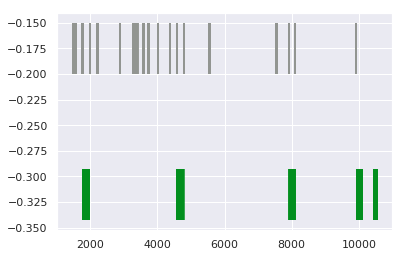

In [29]:
whisking_ind = np.logical_and(np.logical_and(big_df['whisk_vel_norm']>0.4, 
                              big_df['LFP_vel_norm']<0.05),big_df['rotf']<0.05)

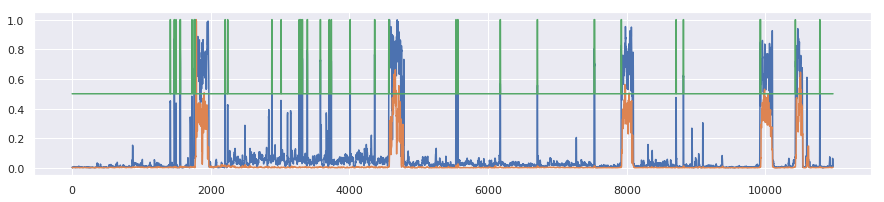

In [30]:
plt.figure(figsize=(15,3))
plt.plot(big_df['whisk_vel_norm'])
plt.plot(big_df['LFP_vel_norm'])
plt.plot(whisking_ind/2+0.5)

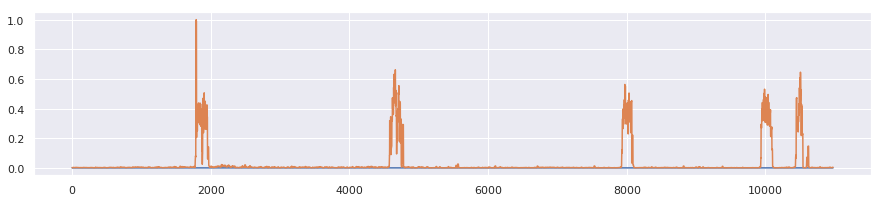

In [35]:
plt.figure(figsize=(15,3))
plt.plot(is_groom_smooth_ds)
plt.plot(big_df['LFP_vel_norm'])

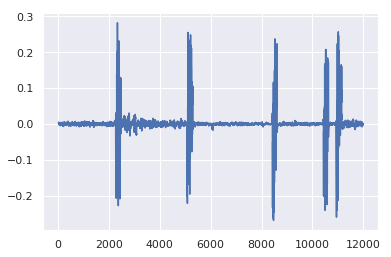

In [36]:
plt.plot(rise_LFP)

In [ ]:
running_ind = big_df['rotf']>0.3


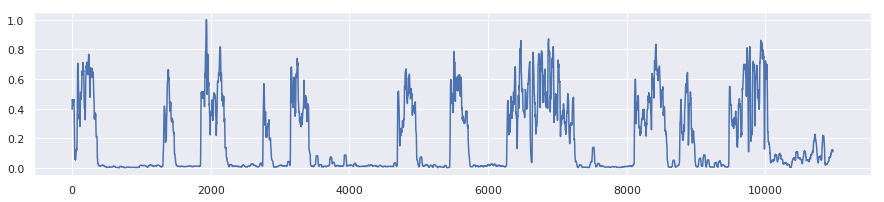

In [30]:
plt.figure(figsize=(15,3))
plt.plot(big_df['rotf'])
plt,scatter(running_ind,no.ones(len(running_ind)))
# plt.plot(big_df['LFP_vel_norm'])

In [17]:
data_pot.shape

(10975, 27)

In [27]:
print(M_jrgeco.shape,
M_jrgeco_std.shape,
M_body_pc.shape,
M_face_pc.shape)

(500, 500, 202) (500, 500, 202) (500, 202) (500, 202)


In [24]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
    

In [26]:
scipy.io.savemat(str(PREPARES / "epochs-rest-to-running") + "/"+mouse+'_raw.mat',
                       {'M_jrgeco':M_jrgeco,
                        'M_jrgeco_std':M_jrgeco_std,
                        'M_chbt':M_chbt,
                        'M_chbt_std':M_chbt_std,
                        'M_rotf':M_rotf,
                        'M_rotf_raw':M_rotf_raw,
                        'M_face_pc':M_face_pc,
                        'M_body_pc':M_body_pc,
                       'M_pupil_pc':M_pupil_pc,
                       'M_pupil_pc_norm':M_pupil_pc_norm,
                        'M_whisk_vel':M_whisk_vel,
                        'M_whisk_vel_norm':M_whisk_vel_norm,
                        'M_nose_vel':M_nose_vel,
                        'M_nose_vel_norm':M_nose_vel_norm,
                        'M_pupil_p_value':M_pupil_p_value,
                        'M_LFP_vel':M_LFP_vel,
                        'M_LFP_vel_norm':M_LFP_vel_norm,
                        'M_RFP_vel':M_RFP_vel,
                        'M_RFP_vel_norm':M_RFP_vel_norm,
                        'M_pupil_pc_norm':M_pupil_pc_norm,
                       'M_day_label':M_day_label,
                        'M_is_groom':M_is_groom,
                       'M_ind_groom_onset':M_ind_groom_onset,
                       'M_y_rise_LFP':M_y_rise_LFP,
                       'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
                       'M_mirrorRFP_vel':M_mirrorRFP_vel,
                       'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
                        'M_mirrorLFP_vel':M_mirrorLFP_vel,
                        'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
                        'M_mirrorRHP_vel':M_mirrorRHP_vel,
                        'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
                        'M_mirrorLHP_vel':M_mirrorLHP_vel,
                        'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm
                       })


save_model(data_joint,str(PREPARES / "epochs-rest-to-running") + "/"+mouse+'_dlc_joint')

In [42]:
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

In [43]:
f = scipy.io.loadmat(str(PREPARES / "epochs-rest-to-running") + "/"+mouse+'_raw.mat')
M_jrgeco=f['M_jrgeco']
M_jrgeco_std=f['M_jrgeco_std']
M_chbt = f['M_chbt']
M_chbt_std = f['M_chbt_std']
M_pupil_pc=f['M_pupil_pc']
M_face_pc=f['M_face_pc']
M_rotf = f['M_rotf']
M_rotf_raw = f['M_rotf_raw']
M_body_pc = f['M_body_pc']
M_whisk_vel = f['M_whisk_vel']
M_whisk_vel_norm = f['M_whisk_vel_norm']
M_nose_vel_norm=f['M_nose_vel_norm']
M_nose_vel = f['M_nose_vel']
M_LFP_vel=f['M_LFP_vel']
M_LFP_vel_norm=f['M_LFP_vel_norm']
M_RFP_vel=f['M_RFP_vel']
M_RFP_vel_norm=f['M_RFP_vel_norm']
M_pupil_pc_norm=f['M_pupil_pc_norm']
                            
M_pupil_p_value=f['M_pupil_p_value']
M_day_label=np.squeeze(f['M_day_label'])
M_is_groom=f['M_is_groom']
M_y_rise_LFP_raw = f['M_y_rise_LFP_raw']
M_y_rise_LFP=f['M_y_rise_LFP']
M_ind_running_onset=np.squeeze(f['M_ind_groom_onset'])

M_mirrorRFP_vel = f['M_mirrorRFP_vel']
M_mirrorRFP_vel_norm = f['M_mirrorRFP_vel_norm']
M_mirrorLFP_vel = f['M_mirrorLFP_vel']
M_mirrorLFP_vel_norm = f['M_mirrorLFP_vel_norm']
M_mirrorRHP_vel = f['M_mirrorRHP_vel']
M_mirrorRHP_vel_norm = f['M_mirrorRHP_vel_norm']
M_mirrorLHP_vel = f['M_mirrorLHP_vel']
M_mirrorLHP_vel_norm = f['M_mirrorLHP_vel_norm']



dlc_joint = load_model('/home/wx2203/Weihao/analysis_locker/f2/'+mouse+'_dlc_joint')

levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()
dlc_joint.index = set_level_values(dlc_joint.index, level='row_level', values=np.repeat(range(len(levelnames)), T))




In [44]:
T_PRE = 200
running_onset = T_PRE

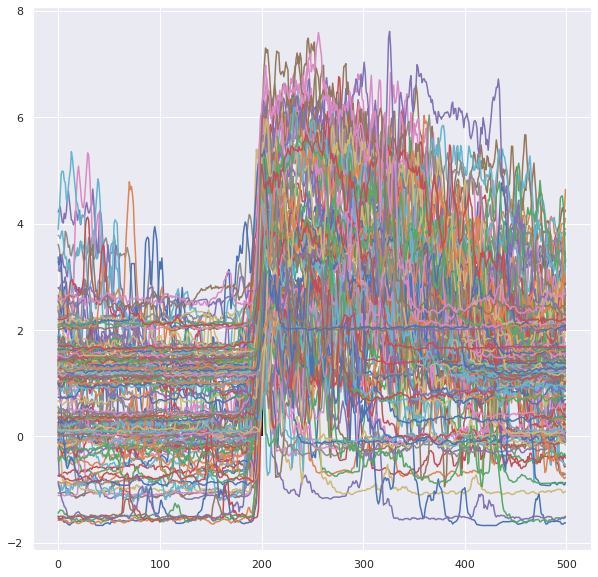

In [45]:
plt.figure(figsize=(10,10))
for i in range(M_body_pc.shape[1]):
    plt.plot(M_body_pc[:,i]+0.02*i)
plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
# plt.xlim([,680])

(180.0, 205.0)

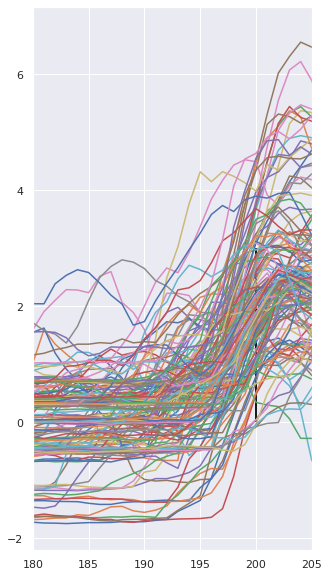

In [46]:
plt.figure(figsize=(5,10))
for i in range(M_rotf.shape[1]):
    plt.plot(M_body_pc[:,i]+0.01*i)
plt.vlines(range(running_onset,running_onset+1),0, 3,linewidth = 2)
plt.xlim([180,205])

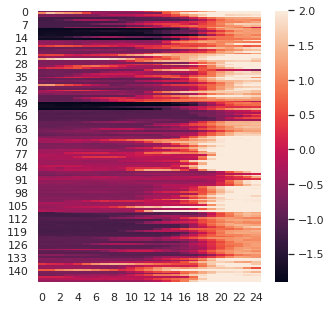

In [47]:
plt.figure(figsize=(5,5))
sns.heatmap(M_body_pc[180:205,:].T,vmax=2)

In [48]:
T_PRE_new = 195
running_onset = T_PRE_new

**first pass**

(113,)


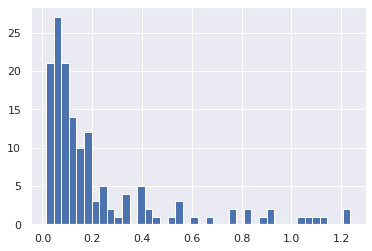

In [50]:
before_running_std = np.std(M_body_pc[:T_PRE_new-5,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.25
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)

In [51]:
print('before ',M_rotf.shape)

M_rotf = M_rotf[:,ss_ind]
M_rotf_raw = M_rotf_raw[:,ss_ind]
M_face_pc = M_face_pc[:,ss_ind]
M_body_pc = M_body_pc[:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_jrgeco_std = M_jrgeco_std[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_chbt_std = M_chbt_std[:,:,ss_ind]
M_pupil_pc = M_pupil_pc[:,ss_ind]
M_whisk_vel = M_whisk_vel[:,ss_ind]
M_whisk_vel_norm = M_whisk_vel_norm[:,ss_ind]
M_nose_vel = M_nose_vel[:,ss_ind]
M_nose_vel_norm = M_nose_vel_norm[:,ss_ind]
M_pupil_p_value = M_pupil_p_value[:,ss_ind]

M_is_groom = M_is_groom[:,ss_ind]
M_y_rise_LFP_raw = M_y_rise_LFP_raw[:,ss_ind]
M_y_rise_LFP = M_y_rise_LFP[:,ss_ind]


M_LFP_vel=M_LFP_vel[:,ss_ind]
M_LFP_vel_norm=M_LFP_vel_norm[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_RFP_vel_norm=M_RFP_vel_norm[:,ss_ind]
M_pupil_pc_norm=M_pupil_pc_norm[:,ss_ind]

M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

dlc_joint=dlc_joint.loc[np.squeeze(np.where(ss_ind==True))]
#reset index
levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()
dlc_joint.index = set_level_values(dlc_joint.index, level='row_level', values=np.repeat(range(len(levelnames)), T))




print('after ',M_mirrorLHP_vel_norm.shape)





before  (500, 147)
after  (500, 113)


(0.0, 280.0)

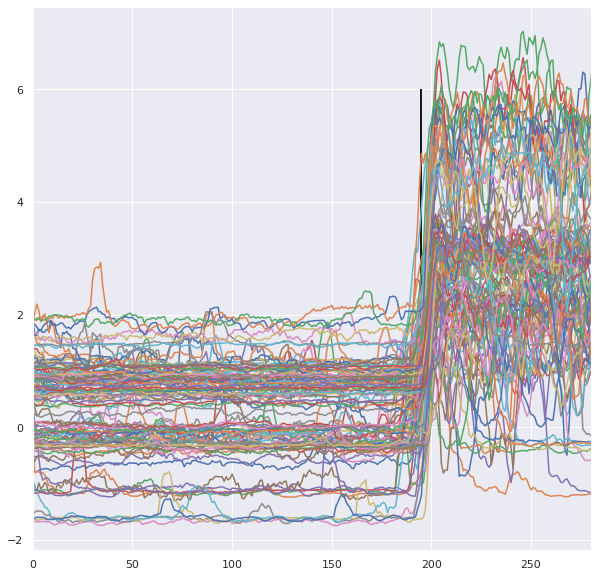

In [52]:
plt.figure(figsize=(10,10))
for i in range(M_body_pc.shape[1]):
    plt.plot(M_body_pc[:,i]+0.02*i)
plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
plt.xlim([0,280])

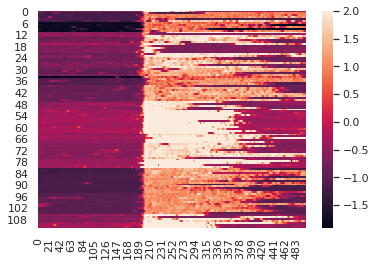

In [53]:
sns.heatmap(M_body_pc.T,vmax=2)

**second pass**

(94,)


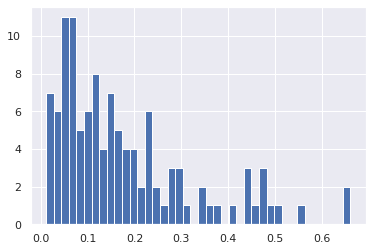

In [54]:
before_running_std = np.std(M_body_pc[T_PRE_new-40:T_PRE_new,:],axis=0)
n, bins, patches = plt.hist(before_running_std,bins=40)
ss = 0.3
ss_ind = before_running_std<ss
print(np.where(ss_ind==True)[0].shape)

In [55]:
print('before ',M_rotf.shape)

M_rotf = M_rotf[:,ss_ind]
M_rotf_raw = M_rotf_raw[:,ss_ind]
M_face_pc = M_face_pc[:,ss_ind]
M_body_pc = M_body_pc[:,ss_ind]
M_day_label = M_day_label[ss_ind]
M_jrgeco = M_jrgeco[:,:,ss_ind]
M_jrgeco_std = M_jrgeco_std[:,:,ss_ind]
M_chbt = M_chbt[:,:,ss_ind]
M_chbt_std = M_chbt_std[:,:,ss_ind]
M_pupil_pc = M_pupil_pc[:,ss_ind]
M_whisk_vel = M_whisk_vel[:,ss_ind]
M_whisk_vel_norm = M_whisk_vel_norm[:,ss_ind]
M_nose_vel = M_nose_vel[:,ss_ind]
M_nose_vel_norm = M_nose_vel_norm[:,ss_ind]
M_pupil_p_value = M_pupil_p_value[:,ss_ind]

M_is_groom = M_is_groom[:,ss_ind]
M_y_rise_LFP_raw = M_y_rise_LFP_raw[:,ss_ind]
M_y_rise_LFP = M_y_rise_LFP[:,ss_ind]


M_LFP_vel=M_LFP_vel[:,ss_ind]
M_LFP_vel_norm=M_LFP_vel_norm[:,ss_ind]
M_RFP_vel=M_RFP_vel[:,ss_ind]
M_RFP_vel_norm=M_RFP_vel_norm[:,ss_ind]
M_pupil_pc_norm=M_pupil_pc_norm[:,ss_ind]


M_mirrorRFP_vel = M_mirrorRFP_vel[:,ss_ind]
M_mirrorRFP_vel_norm = M_mirrorRFP_vel_norm[:,ss_ind]
M_mirrorLFP_vel = M_mirrorLFP_vel[:,ss_ind]
M_mirrorLFP_vel_norm = M_mirrorLFP_vel_norm[:,ss_ind]
M_mirrorRHP_vel = M_mirrorRHP_vel[:,ss_ind]
M_mirrorRHP_vel_norm = M_mirrorRHP_vel_norm[:,ss_ind]
M_mirrorLHP_vel = M_mirrorLHP_vel[:,ss_ind]
M_mirrorLHP_vel_norm = M_mirrorLHP_vel_norm[:,ss_ind]

dlc_joint=dlc_joint.loc[np.squeeze(np.where(ss_ind==True))]
#reset index
levelnames = dlc_joint.index.get_level_values(0).drop_duplicates()
dlc_joint.index = set_level_values(dlc_joint.index, level='row_level', values=np.repeat(range(len(levelnames)), T))



print('after ',M_mirrorLHP_vel_norm.shape)





before  (500, 113)
after  (500, 94)


(0.0, 280.0)

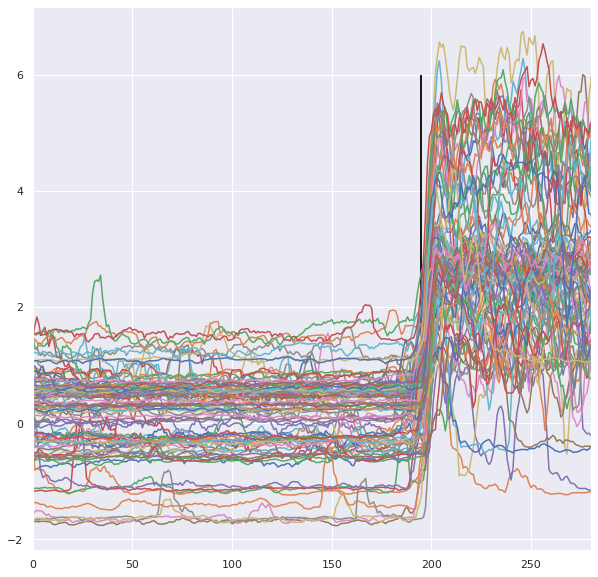

In [56]:
plt.figure(figsize=(10,10))
for i in range(M_body_pc.shape[1]):
    plt.plot(M_body_pc[:,i]+0.02*i)
plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
plt.xlim([0,280])

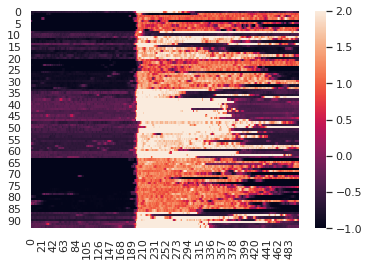

In [57]:
sns.heatmap(M_body_pc.T,vmin=-1,vmax=2)

(0.0, 320.0)

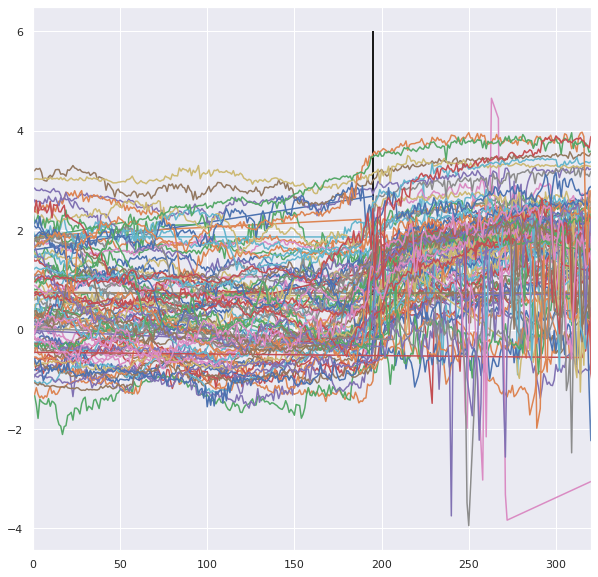

In [58]:
plt.figure(figsize=(10,10))
for i in range(M_pupil_pc.shape[1]):
    plt.plot(M_pupil_pc[:,i]+0.02*i)
plt.vlines(range(running_onset,running_onset+1),0, 6,linewidth = 2)
plt.xlim([0,320])

In [59]:
scipy.io.savemat('/home/wx2203/Weihao/analysis_locker/f2/'+mouse+'_filtered.mat',
                       {'M_jrgeco':M_jrgeco,
                        'M_jrgeco_std':M_jrgeco_std,
                        'M_chbt':M_chbt,
                        'M_chbt_std':M_chbt_std,
                        'M_rotf':M_rotf,
                        'M_rotf_raw':M_rotf_raw,
                        'M_face_pc':M_face_pc,
                        'M_body_pc':M_body_pc,
                       'M_pupil_pc':M_pupil_pc,
                        'M_whisk_vel':M_whisk_vel,
                        'M_whisk_vel_norm':M_whisk_vel_norm,
                        'M_nose_vel':M_nose_vel,
                        'M_nose_vel_norm':M_nose_vel_norm,
                        'M_pupil_p_value':M_pupil_p_value,
                        'M_LFP_vel':M_LFP_vel,
                        'M_LFP_vel_norm':M_LFP_vel_norm,
                        'M_RFP_vel':M_RFP_vel,
                        'M_RFP_vel_norm':M_RFP_vel_norm,
                        'M_pupil_pc_norm':M_pupil_pc_norm,
                       'M_day_label':M_day_label,
                        'M_is_groom':M_is_groom,
                       'M_ind_groom_onset':M_ind_groom_onset,
                       'M_y_rise_LFP':M_y_rise_LFP,
                       'M_y_rise_LFP_raw':M_y_rise_LFP_raw,
                      'M_mirrorRFP_vel':M_mirrorRFP_vel,
                       'M_mirrorRFP_vel_norm':M_mirrorRFP_vel_norm,
                        'M_mirrorLFP_vel':M_mirrorLFP_vel,
                        'M_mirrorLFP_vel_norm':M_mirrorLFP_vel_norm,
                        'M_mirrorRHP_vel':M_mirrorRHP_vel,
                        'M_mirrorRHP_vel_norm':M_mirrorRHP_vel_norm,
                        'M_mirrorLHP_vel':M_mirrorLHP_vel,
                        'M_mirrorLHP_vel_norm':M_mirrorLHP_vel_norm})



save_model(dlc_joint,'/home/wx2203/Weihao/analysis_locker/f2/'+mouse+'_dlc_joint_filtered')

